# Анализ лояльности пользователей Яндекс Афиши

# Цели и задачи проекта

**Цель проекта:**
Повышение уровня удержания клиентов и увеличение доли повторных покупателей на основе анализа поведения пользователей.

**Ключевые задачи:**

1. **Загрузка и первичный анализ данных:** Обработка информации Яндекс Афиши (информация о пользователях и о заказах: выручка от заказа, количество купленных билетов, дата покупки и тип устройства, с которого производился заказ, промежуток временим между заказами, а также город и регион, в котором происходил заказ).

2. **Подготовка данных:** Проверка датасета после предобработки на SQL. Оценка качества данных, представление нужной выборки для исследования , определение ошибок и т.д.


3. **Исследовательский анализ данных (EDA) о взаимодействии пользователей с сервисом:** 

    - Выявить ключевые характеристики и паттерны поведения пользователей, склонных к повторным покупкам.

    - Определить факторы, влияющие на возврат пользователей на платформу и совершение повторных заказов.
    

4. **Разработка рекомендаций:** Сформулировать рекомендации для маркетинга по выявлению перспективных клиентов, настройке таргетинга и оптимизации бюджетов.

In [1]:
get_ipython().system('pip install sqlalchemy psycopg2-binary phik python-dotenv -q')

## Этапы выполнения проекта

### 1. Загрузка данных и их предобработка

---

<font color='#777778'> **Задача 1.1:** Напишите SQL-запрос, выгружающий в датафрейм pandas необходимые данные. 

Выгрузка из базы данных SQL должна позволить собрать следующие данные:

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (`mobile` — мобильные устройства, `desktop` — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа (используйте данные `created_dt_msk`);
- `order_ts` — дата и время создания заказа (используйте данные `created_ts_msk`);
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `event_name` — название мероприятия (используйте данные `event_name_code`);
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.</font>

---


In [2]:
# Импорт необходимых библиотек
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sqlalchemy import create_engine 
from dotenv import load_dotenv
import phik
from phik import resources, report

# Настройки отображения
pd.set_option('display.max_columns', None)

**Загрузка данных и первичный обзор выборки**

Для проведения исследовательского анализа лояльности пользователей сервиса Яндекс Афиша выполняется выгрузка данных из аналитической базы PostgreSQL. Запрос формирует выборку заказов, дополненную временными лагами между покупками (`days_since_prev`), характеристиками событий и географическими метками.

In [3]:
# Загрузка переменных окружения
load_dotenv()

# Данные для подключения к базе данных из .env
db_config = {
    'user': os.getenv('DB_USER'),
    'pwd': os.getenv('DB_PASSWORD'),
    'host': os.getenv('DB_HOST'),
    'port': int(os.getenv('DB_PORT')),
    'db': os.getenv('DB_NAME')
}

In [4]:
# Формирование строки подключения
connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

In [5]:
# Создание соединения с базой данных
engine = create_engine(connection_string)

In [6]:
# SQL-запрос для выгрузки данных согласно заданных параметров
query = """
SELECT 
    p.user_id,
    p.device_type_canonical,
    p.order_id,
    p.created_dt_msk AS order_dt,
    p.created_ts_msk AS order_ts,
    p.currency_code,
    p.revenue,
    p.tickets_count,
    EXTRACT(DAY FROM (p.created_dt_msk - LAG(p.created_dt_msk) OVER (PARTITION BY p.user_id ORDER BY p.created_dt_msk)))::integer AS days_since_prev,
    p.event_id,
    e.event_name_code AS event_name,
    e.event_type_main,
    p.service_name,
    r.region_name,
    c.city_name
FROM afisha.purchases p
LEFT JOIN afisha.events e ON p.event_id = e.event_id
LEFT JOIN afisha.city c ON e.city_id = c.city_id
LEFT JOIN afisha.regions r ON c.region_id = r.region_id
WHERE 
    p.device_type_canonical IN ('mobile', 'desktop')
    AND (e.event_type_main != 'фильм')
ORDER BY p.user_id;
"""

In [7]:
# Выполнение запроса и загрузка данных в DataFrame
df = pd.read_sql_query(query, engine)

In [8]:
# Проверка подключения (выполняем тестовый запрос)
test_query = '''
SELECT *
FROM afisha.purchases
LIMIT 5
'''

# Тестовый запрос (первые 5 строк из purchases)
test_df = pd.read_sql_query(test_query, con=engine)
test_df

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total
0,1,3ebd0c4b59f6bdd,2024-08-08,2024-08-08 15:01:11,555432,нет,16,rub,mobile,568.43,Облачко,2,5684.33
1,30,1a66f181a803c75,2024-09-05,2024-09-05 19:44:21,149337,нет,16,rub,mobile,575.08,Край билетов,2,6389.80
2,59,1a66f181a803c75,2024-07-25,2024-07-25 10:09:41,269938,нет,12,rub,desktop,402.51,Лови билет!,4,6708.45
3,88,7997823870f2b1b,2024-09-26,2024-09-26 16:03:44,561834,нет,18,rub,mobile,487.94,Мой билет,2,3753.35
4,117,1c5bac640c12e86,2024-09-15,2024-09-15 14:18:07,568660,нет,0,rub,mobile,8.95,Лови билет!,2,447.38


Данные успешно выгружены из базы данных. Проведено тестовое подключение к схеме purchases.

---

<font color='#777778'> **Задача 1.2:** Изучите общую информацию о выгруженных данных. Оцените корректность выгрузки и объём полученных данных.

Предположите, какие шаги необходимо сделать на стадии предобработки данных — например, скорректировать типы данных.

Зафиксируйте основную информацию о данных в кратком промежуточном выводе.</font>

---

In [9]:
# Вывод информации о загруженных данных
print(f"\nКоличество строк: {len(df)}")
print(f"\nКоличество столбцов: {len(df.columns)}")
print(f"\nНазвания столбцов:")
list(df.columns)


Количество строк: 290611

Количество столбцов: 15

Названия столбцов:


['user_id',
 'device_type_canonical',
 'order_id',
 'order_dt',
 'order_ts',
 'currency_code',
 'revenue',
 'tickets_count',
 'days_since_prev',
 'event_id',
 'event_name',
 'event_type_main',
 'service_name',
 'region_name',
 'city_name']

Количество столбцов и состав признаков соответствуют структуре базы данных.

In [10]:
# Вывод информации о загруженных данных
print("\nПервые 10 строк данных:")
df.head(10)


Первые 10 строк данных:


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк
5,000898990054619,mobile,2613713,2024-10-23,2024-10-23 15:12:00,rub,902.74,3,19.0,500862,9cc55c15-4375-4129-9979-3129688ba1b4,концерты,Облачко,Лугоградская область,Кристалевск
6,00096d1f542ab2b,desktop,6636941,2024-08-15,2024-08-15 16:48:48,rub,917.83,4,NaN,201953,2f98d69f-4e60-4ffc-8f16-e539383526b1,театр,Край билетов,Каменевский регион,Глиногорск
7,000a55a418c128c,mobile,4657981,2024-09-29,2024-09-29 19:39:12,rub,47.78,1,NaN,265857,0d876e01-851e-458b-ba61-753e0e0c4063,театр,Лучшие билеты,Поленовский край,Дальнозолотск
8,000a55a418c128c,mobile,4657952,2024-10-15,2024-10-15 10:29:04,rub,74.84,2,16.0,271579,ddc795f8-7ef8-4eb0-b299-cb3e6ee24ba1,театр,Лучшие билеты,Поленовский край,Дальнозолотск
9,000cf0659a9f40f,mobile,6818017,2024-06-20,2024-06-20 10:35:26,rub,1421.91,4,NaN,516728,11be386f-7cb7-4aa1-a8e4-ba73a29c1af2,концерты,Лови билет!,Широковская область,Радужнополье


In [11]:
# Вывод информации о загруженных данных

print("Информация о DataFrame:")
df.info()

Информация о DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name        

Типы столбцов в целом соответствуют содержанию данных, наименования приведены к стандарту snake_case. Память числовых столбцов избыточна (int64, float64), целесообразно оптимизировать разрядность на этапе предобработки.

In [12]:
# Вывод информации о загруженных данных
print("\nСтатистика по числовым колонкам:")
df.describe()


Статистика по числовым колонкам:


,order_id,revenue,tickets_count,days_since_prev,event_id
count,2.906110e+05,290611.000000,290611.000000,268678.000000,290611.000000
mean,4.326225e+06,625.584360,2.754311,3.222381,438019.834992
std,2.497551e+06,1227.693064,1.170620,11.350509,147423.078841
min,1.000000e+00,-90.760000,1.000000,0.000000,4436.000000
25%,2.163618e+06,116.850000,2.000000,0.000000,361772.000000
50%,4.326366e+06,356.010000,3.000000,0.000000,498275.000000
75%,6.488330e+06,810.130000,4.000000,1.000000,546287.000000
max,8.653108e+06,81174.540000,57.000000,148.000000,592325.000000


В распределении признаков `revenue`, `tickets_count` и `days_since_prev` наблюдается выраженная асимметрия. В столбце `revenue` присутствуют отрицательные значения, требующие удаления.

In [13]:
# Проверка количества пропусков по всем полям
df.isnull().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
event_type_main              0
service_name                 0
region_name                  0
city_name                    0
dtype: int64

In [14]:
# Детальный отчет по пропускам
missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Пропущено значений': missing_values,
    'Процент пропусков': missing_percent.round(2)
})
missing_df[missing_df['Пропущено значений'] > 0]

,Пропущено значений,Процент пропусков
days_since_prev,21933,7.55


Пропуски зафиксированы только в столбце `days_since_prev` (7.55%), что соответствует первой покупке клиентов и является естественной особенностью расчета временного интервала.

In [15]:
# Анализ уникальных идентификаторов в выборке
print(f"Уникальных user_id: {df['user_id'].nunique()}")
print(f"Уникальных order_id: {df['order_id'].nunique()}")
print(f"Уникальных event_id: {df['event_id'].nunique()}")
print(f"Соотношение order_id / строки: {df['order_id'].nunique() / len(df):.2%}")

Уникальных user_id: 21933
Уникальных order_id: 290611
Уникальных event_id: 22427
Соотношение order_id / строки: 100.00%


Всего в датасете представлены 21933 пользователя, общее количество мероприятий - 22427. Всего было совершено 290611 заказов, пропусков в строках не обнаружено.

In [16]:
# Анализ распределения значений категориальных признаков
categorical_columns = ['device_type_canonical', 'currency_code', 'event_type_main', 'service_name', 'region_name', 'city_name']
for col in categorical_columns:
    if col in df.columns:
        print(f"\n{col}:")
        print(f"  Уникальных значений: {df[col].nunique()}")
        print(f"  Топ значений: {df[col].value_counts().head(5).to_dict()}")


device_type_canonical:
  Уникальных значений: 2
  Топ значений: {'mobile': 232490, 'desktop': 58121}

currency_code:
  Уникальных значений: 2
  Топ значений: {'rub': 285542, 'kzt': 5069}

event_type_main:
  Уникальных значений: 7
  Топ значений: {'концерты': 115276, 'театр': 67321, 'другое': 65867, 'спорт': 21911, 'стендап': 13393}

service_name:
  Уникальных значений: 36
  Топ значений: {'Билеты без проблем': 63519, 'Лови билет!': 41124, 'Билеты в руки': 40343, 'Мой билет': 34839, 'Облачко': 26642}

region_name:
  Уникальных значений: 81
  Топ значений: {'Каменевский регион': 91058, 'Североярская область': 44049, 'Широковская область': 16457, 'Медовская область': 13901, 'Озернинский край': 10476}

city_name:
  Уникальных значений: 352
  Топ значений: {'Глиногорск': 89446, 'Озёрск': 43910, 'Радужсвет': 13711, 'Радужнополье': 8741, 'Верховино': 6579}


In [17]:
# Анализ временного диапазона датасета
print(f"Минимальная дата заказа: {df['order_dt'].min()}")
print(f"Максимальная дата заказа: {df['order_dt'].max()}")
print(f"Период данных: {(df['order_dt'].max() - df['order_dt'].min()).days} дней")

Минимальная дата заказа: 2024-06-01 00:00:00
Максимальная дата заказа: 2024-10-31 00:00:00
Период данных: 152 дней


In [18]:
# Анализ частоты повторных покупок и интервалов
print(f"Всего записей: {len(df)}")
print(f"Единичных покупок (days_since_prev = NULL): {df['days_since_prev'].isnull().sum()}")
print(f"Повторных покупок: {df['days_since_prev'].notnull().sum()}")
print(f"Процент повторных покупок: {(df['days_since_prev'].notnull().sum() / len(df) * 100):.2f}%")
if df['days_since_prev'].notnull().sum() > 0:
    print(f"Среднее количество дней между покупками: {df['days_since_prev'].mean():.2f}")
    print(f"Медианное количество дней между покупками: {df['days_since_prev'].median():.2f}")

Всего записей: 290611
Единичных покупок (days_since_prev = NULL): 21933
Повторных покупок: 268678
Процент повторных покупок: 92.45%
Среднее количество дней между покупками: 3.22
Медианное количество дней между покупками: 0.00


В среднем 92 человека из 100 совершали повторные заказы. Разница между средним и медианным количеством дней между заказами говорит о наличии выбросов, что будет исказать исследование.

**Общая характерстика выборки:** 
 
  - В датасете представлена статистика по данным за 152 дня (5 месяцев) с 1 июня по 31 октября 2024 г.
 
  - Всего в датасете представлено 290 611 записей, что достаточно для исследовательского анализа
 
  - Уникальных пользователей — 21 933.
 
  - Из 290 611 заказов, 281 879 (92,45%) — повторные. Это означает, что платформа успешно удерживает пользователей. Большинство заказов совершают уже существующие клиенты.

**Качество данных:**

  - Из 15 столбцов тоолько в одном есть пропуски - `days_since_prev` (7.59%), в котором отмечен промежуток между повторными заказами.

  - Категориальные данные чистые, без "мусорных" значений. Реализована понятная логика столбцов (регионы, города, типы мероприятий и т.д.)

  - В столбцах с количественными данными выделяется столбец `revenue` с отрицательными значениями и большим расходжением среднего и медианного. В `days_since_prev` также отмечается расхождение между средним и медианным.

**Временные характерситики:**

  - средний интервал возврата клиентов 3,25 дня говорит о том, что пользователи возвращаются часто.
    
  - Медианное значение 0 дней — большинство клиентов возвращаются в тот же день или же покупают билеты на мероприятия разными заказами.
  
  - максимальный интервал — 148 дней. Есть "спящие" пользователи

  - Платформа имеет высокий возврат пользовтелей.

**Главный вывод:**

Данные высокого качества, репрезентативны и достаточны для глубокого анализа лояльности. Платформа демонстрирует отличное удержание (92% повторных покупок). Ключевая задача - понять, какие именно факторы (устройство, регион, жанр, оператор) влияют на переход пользователей в категорию супер-лояльных (5+ заказов).

---

###  2. Предобработка данных

<font color='#777778'> Выполните все стандартные действия по предобработке данных:

---

**Задача 2.1:** Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведите выручку к единой валюте — российскому рублю.

Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — `final_tickets_tenge_df.csv`. Его можно загрузить по пути `https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')`

Значения в рублях представлено для 100 тенге.

Результаты преобразования сохраните в новый столбец `revenue_rub`.</font>

---


In [19]:
# Загрузка данных о курсе тенге
url_tenge = 'https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv'
tenge_df = pd.read_csv(url_tenge)
tenge_df.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [20]:
# Подготовка данных о курсах: приведение даты к datetime и индексация
tenge_df['data'] = pd.to_datetime(tenge_df['data'])
tenge_df.set_index('data', inplace=True)
tenge_df.sort_index(inplace=True)

In [21]:
# Приведение выручки к единой валюте — российскому рублю
df['revenue_rub'] = df['revenue'].copy()

kzt_mask = df['currency_code'] == 'kzt'

# Пересчет суммы для тенге: (сумма / 100) * курс на дату заказа
df.loc[kzt_mask, 'revenue_rub'] = (
    df.loc[kzt_mask, 'revenue'] / 100 * 
    df.loc[kzt_mask, 'order_dt'].dt.normalize().map(tenge_df['curs'])
)

In [22]:
# Проверка результата

print("Примеры заказов в тенге (первые 5):")
print(df[kzt_mask][['order_dt', 'currency_code', 'revenue', 'revenue_rub']].head())

Примеры заказов в тенге (первые 5):
      order_dt currency_code   revenue  revenue_rub
70  2024-09-17           kzt    518.10    98.503762
89  2024-09-02           kzt    347.18    65.731589
96  2024-09-09           kzt    328.77    61.148261
277 2024-06-11           kzt  22021.55  4380.702898
460 2024-06-04           kzt   7397.66  1478.296591


In [23]:
# Суммарная выручка по исходным валютам после пересчета

df.groupby('currency_code')['revenue_rub'].agg(['count', 'sum'])

,count,sum
currency_code,,
kzt,5069,4.974337e+06
rub,285542,1.564810e+08


In [24]:
# Определение суммы значений revenue И revenue_rub 

# Общая сумма по всем заказам

total_revenue = df['revenue'].sum()
total_revenue_rub = df['revenue_rub'].sum()

print(f"Общая сумма revenue (в исходных валютах): {total_revenue:,.2f}")
print(f"Общая сумма revenue_rub (все в рублях): {total_revenue_rub:,.2f}")
print(f"Разница: {total_revenue_rub - total_revenue:,.2f}")

Общая сумма revenue (в исходных валютах): 181,801,696.49
Общая сумма revenue_rub (все в рублях): 161,455,330.62
Разница: -20,346,365.87


In [25]:
# Выведем значения столбцов обновленного датасета

list(df.columns)

['user_id',
 'device_type_canonical',
 'order_id',
 'order_dt',
 'order_ts',
 'currency_code',
 'revenue',
 'tickets_count',
 'days_since_prev',
 'event_id',
 'event_name',
 'event_type_main',
 'service_name',
 'region_name',
 'city_name',
 'revenue_rub']

In [26]:
# Проверка пропущенных значений в новом столбце

df['revenue_rub'].isnull().sum()

0

Конвертация валюты завершена успешно: создан унифицированный столбец `revenue_rub`. Пропусков в новых значениях не обнаружено.

---

<font color='#777778'> **Задача 2.2:**

- Проверьте данные на пропущенные значения. Если выгрузка из SQL была успешной, то пропуски должны быть только в столбце `days_since_prev`.
- Преобразуйте типы данных в некоторых столбцах, если это необходимо. Обратите внимание на данные с датой и временем, а также на числовые данные, размерность которых можно сократить.
- Изучите значения в ключевых столбцах. Обработайте ошибки, если обнаружите их.
    - Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо.
    - Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха.
        
        Важные показатели в рамках поставленной задачи — это выручка с заказа (`revenue_rub`) и количество билетов в заказе (`tickets_count`), поэтому в первую очередь проверьте данные в этих столбцах.
        
        Если обнаружите выбросы в поле `revenue_rub`, то отфильтруйте значения по 99 перцентилю.

После предобработки проверьте, были ли отфильтрованы данные. Если были, то оцените, в каком объёме. Сформулируйте промежуточный вывод, зафиксировав основные действия и описания новых столбцов.
</font>
---

In [27]:
# Выврд общей информации о DataFrame

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

In [28]:
# Оптимизация типов данных: понижение разрядности числовых полей

# days_since_prev переводим в целочисленный тип с поддержкой отсутствующих значений
df['days_since_prev'] = df['days_since_prev'].astype('Int64')

# Оптимизация целочисленных столбцов
for col in ['order_id', 'tickets_count', 'event_id']:
    df[col] = pd.to_numeric(df[col], downcast='integer')

# Оптимизация вещественных столбцов
for col in ['revenue', 'revenue_rub']:
    df[col] = pd.to_numeric(df[col], downcast='float')

In [29]:
# Вывод обновленной информации о DataFrame

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int32         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float32       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  Int64         
 9   event_id               290611 non-null  int32         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

Понижение разрядности прошло корректно, потребление памяти датафреймом уменьшилось.

In [30]:
# Проверка пропущенных значений по столбцам
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    'Пропущено': missing,
    'Процент': missing_percent.round(2)
})
missing_df[missing_df['Пропущено'] > 0]

,Пропущено,Процент
days_since_prev,21933,7.55


Пропуски только в days_since_prev

In [31]:
# Количество уникальных значений в категориальных признаках
categorical_columns = ['device_type_canonical', 'currency_code', 'event_type_main', 
                       'service_name', 'region_name', 'city_name']

pd.DataFrame({
    'Признак': categorical_columns,
    'Уникальных значений': [df[col].nunique() for col in categorical_columns]
})

,Признак,Уникальных значений
0,device_type_canonical,2
1,currency_code,2
2,event_type_main,7
3,service_name,36
4,region_name,81
5,city_name,352


In [32]:
# Детальный состав категорий для ключевых признаков
for column in ['device_type_canonical', 'event_type_main', 'service_name']:
    display(pd.DataFrame({
        'Количество': df[column].value_counts(dropna=False),
        'Доля, %': (df[column].value_counts(dropna=False, normalize=True) * 100).round(2)
    }).head(10))

,Количество,"Доля, %"
mobile,232490,80.0
desktop,58121,20.0


,Количество,"Доля, %"
концерты,115276,39.67
театр,67321,23.17
другое,65867,22.67
спорт,21911,7.54
стендап,13393,4.61
выставки,4854,1.67
ёлки,1989,0.68


,Количество,"Доля, %"
Билеты без проблем,63519,21.86
Лови билет!,41124,14.15
Билеты в руки,40343,13.88
Мой билет,34839,11.99
Облачко,26642,9.17
Лучшие билеты,17774,6.12
Весь в билетах,16849,5.80
Прачечная,10273,3.53
Край билетов,6207,2.14
Тебе билет!,5228,1.80


In [33]:
# Анализ редких категорий (с долей менее 1% от выборки)
threshold = len(df) * 0.01
summary_data = []
all_rare_mask = pd.Series(False, index=df.index)

for column in categorical_columns:
    value_counts = df[column].value_counts(dropna=False)
    rare_values = value_counts[value_counts < threshold]
    
    if len(rare_values) > 0:
        rare_mask = df[column].isin(rare_values.index)
        all_rare_mask = all_rare_mask | rare_mask
        rare_records = rare_mask.sum()
    else:
        rare_records = 0
    
    summary_data.append({
        'Признак': column,
        'Уникальных': df[column].nunique(),
        'Редких (<1%)': len(rare_values),
        'Записей в редких': rare_records
    })

display(pd.DataFrame(summary_data))
print(f"Всего записей в редких категориях: {all_rare_mask.sum()} ({all_rare_mask.sum()/len(df)*100:.2f}%)")

,Признак,Уникальных,Редких (<1%),Записей в редких
0,device_type_canonical,2,0,0
1,currency_code,2,0,0
2,event_type_main,7,1,1989
3,service_name,36,24,18272
4,region_name,81,63,46348
5,city_name,352,334,65291


Всего записей в редких категориях: 83681 (28.79%)


In [34]:
# Статистика числовых признаков до фильтрации выбросов
rows_before = len(df)
df[['revenue_rub', 'tickets_count', 'days_since_prev']].describe().round(2)

,revenue_rub,tickets_count,days_since_prev
count,290611.00,290611.00,268678.00
mean,555.57,2.75,3.22
std,875.50,1.17,11.35
min,-90.76,1.00,0.00
25%,113.97,2.00,0.00
50%,351.14,3.00,0.00
75%,802.05,4.00,1.00
max,81174.54,57.00,148.00


In [35]:
# Подсчет аномальных записей (отрицательные и нулевые значения)
negative_revenue = (df['revenue_rub'] < 0).sum()
zero_revenue = (df['revenue_rub'] == 0).sum()
zero_tickets = (df['tickets_count'] == 0).sum()

pd.DataFrame({
    'Аномалия': ['Отрицательная выручка', 'Нулевая выручка', 'Нулевое количество билетов'],
    'Количество строк': [negative_revenue, zero_revenue, zero_tickets]
})

,Аномалия,Количество строк
0,Отрицательная выручка,381
1,Нулевая выручка,5526
2,Нулевое количество билетов,0


В данном случае нулевые и отрицательные значения будут искажать наш исследовательский анализ. Можно удалить их для более качественной оценки данных.

In [36]:
# Исключение записей с неположительной выручкой и некорректным числом билетов
df_clean = df[
    (df['revenue_rub'] > 0) & 
    (df['tickets_count'] > 0)
].copy()

rows_removed_basic = rows_before - len(df_clean)
print(f"Удалено записей с неположительной выручкой/билетами: {rows_removed_basic}")

Удалено записей с неположительной выручкой/билетами: 5907


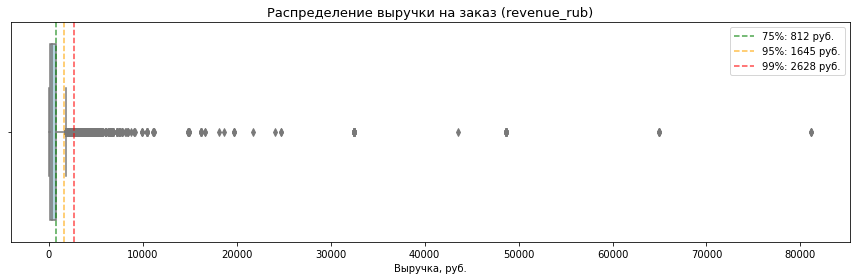

,Значение
75-й перцентиль,811.61 руб.
95-й перцентиль,1645.20 руб.
99-й перцентиль,2628.42 руб.


In [37]:
# Расчет перцентилей и визуализация распределения выручки
percentile_75 = df_clean['revenue_rub'].quantile(0.75)
percentile_95 = df_clean['revenue_rub'].quantile(0.95)
percentile_99 = df_clean['revenue_rub'].quantile(0.99)

plt.figure(figsize=(12, 4))
sns.boxplot(x=df_clean['revenue_rub'], color='lightblue', orient='h')
plt.title('Распределение выручки на заказ (revenue_rub)', fontsize=13)
plt.xlabel('Выручка, руб.')

plt.axvline(x=percentile_75, color='green', linestyle='--', alpha=0.7, label=f'75%: {percentile_75:.0f} руб.')
plt.axvline(x=percentile_95, color='orange', linestyle='--', alpha=0.7, label=f'95%: {percentile_95:.0f} руб.')
plt.axvline(x=percentile_99, color='red', linestyle='--', alpha=0.7, label=f'99%: {percentile_99:.0f} руб.')

plt.legend()
plt.tight_layout()
plt.show()

pd.Series({
    '75-й перцентиль': f"{percentile_75:.2f} руб.",
    '95-й перцентиль': f"{percentile_95:.2f} руб.",
    '99-й перцентиль': f"{percentile_99:.2f} руб."
}).to_frame(name='Значение')

In [38]:
# Отсечение экстремальных выбросов выше 99-го перцентиля выручки
rows_before_outliers = len(df_clean)
df_final = df_clean[df_clean['revenue_rub'] <= percentile_99].copy()
rows_removed_outliers = rows_before_outliers - len(df_final)

print(f"Порог 99-го перцентиля: {percentile_99:.2f} руб.")
print(f"Удалено выбросов: {rows_removed_outliers} ({(rows_removed_outliers/rows_before_outliers*100):.2f}%)")

Порог 99-го перцентиля: 2628.42 руб.
Удалено выбросов: 2825 (0.99%)


In [39]:
# Контроль временных рамок очищенных данных
pd.Series({
    'Начало периода': df_final['order_dt'].min().date(),
    'Окончание периода': df_final['order_dt'].max().date(),
    'Всего дней': (df_final['order_dt'].max() - df_final['order_dt'].min()).days
}).to_frame(name='Период исследования')

,Период исследования
Начало периода,2024-06-01
Окончание периода,2024-10-31
Всего дней,152


In [40]:
# Сводный отчет по этапам фильтрации
total_removed = rows_before - len(df_final)

pd.DataFrame({
    'Этап': [
        'Исходные данные',
        'Неположительная выручка',
        'Выбросы (выше 99-го перцентиля)',
        'Итоговый датасет'
    ],
    'Количество записей': [
        rows_before,
        negative_revenue + zero_revenue,
        rows_removed_outliers,
        len(df_final)
    ]
})

,Этап,Количество записей
0,Исходные данные,290611
1,Неположительная выручка,5907
2,Выбросы (выше 99-го перцентиля),2825
3,Итоговый датасет,281879


In [41]:
# Фиксация очищенного датафрейма
df = df_final.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 281879 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                281879 non-null  object        
 1   device_type_canonical  281879 non-null  object        
 2   order_id               281879 non-null  int32         
 3   order_dt               281879 non-null  datetime64[ns]
 4   order_ts               281879 non-null  datetime64[ns]
 5   currency_code          281879 non-null  object        
 6   revenue                281879 non-null  float32       
 7   tickets_count          281879 non-null  int8          
 8   days_since_prev        260497 non-null  Int64         
 9   event_id               281879 non-null  int32         
 10  event_name             281879 non-null  object        
 11  event_type_main        281879 non-null  object        
 12  service_name           281879 non-null  obje

In [42]:
# Проверка и удаление явных дубликатов
initial_shape = df.shape
df = df.drop_duplicates()
explicit_duplicates_removed = initial_shape[0] - df.shape[0]

print(f"Удалено явных дубликатов: {explicit_duplicates_removed}")
print(f"Размерность датасета: {df.shape}")

Удалено явных дубликатов: 0
Размерность датасета: (281879, 16)


In [43]:
# Поиск групп с потенциальными неявными дубликатами (одинаковый пользователь, событие, билеты, сумма)
group_cols = ['user_id', 'event_id', 'tickets_count', 'revenue_rub']

duplicate_groups = df.groupby(group_cols).size().reset_index(name='count')
duplicate_groups = duplicate_groups[duplicate_groups['count'] > 1]

total_duplicate_records = duplicate_groups['count'].sum()
total_groups = len(duplicate_groups)

pd.Series({
    'Групп с потенциальными повторами': total_groups,
    'Всего записей в этих группах': total_duplicate_records,
    'Доля от текущего датасета, %': round(total_duplicate_records / len(df) * 100, 2)
}).to_frame(name='Показатель')

,Показатель
Групп с потенциальными повторами,39156.00
Всего записей в этих группах,106406.00
"Доля от текущего датасета, %",37.75


In [44]:
# Пример структуры группы потенциальных дубликатов
sample_group = duplicate_groups.iloc[0]
sample_condition = (
    (df['user_id'] == sample_group['user_id']) & 
    (df['event_id'] == sample_group['event_id']) & 
    (df['tickets_count'] == sample_group['tickets_count']) & 
    (df['revenue_rub'] == sample_group['revenue_rub'])
)

df[sample_condition][['order_id', 'order_dt', 'order_ts', 'device_type_canonical', 'revenue_rub']]

,order_id,order_dt,order_ts,device_type_canonical,revenue_rub
12,6818104,2024-06-20,2024-06-20 12:46:11,mobile,710.950012
15,6818249,2024-06-20,2024-06-20 10:49:48,mobile,710.950012


In [45]:
# Поиск и удаление дубликатов с разницей менее 1 минуты

before_removal_size = df.shape[0]

# Поиск и фильтрация технических дубликатов с интервалом между заказами менее 60 секунд
df_sorted = df.sort_values(['user_id', 'event_id', 'tickets_count', 'order_ts'])
df_sorted['time_diff'] = df_sorted.groupby(group_cols)['order_ts'].diff().dt.total_seconds()

orders_to_remove = df_sorted[df_sorted['time_diff'] < 60]['order_id'].tolist()
removed_count = len(orders_to_remove)

print(f"Найдено технических дубликатов (< 60 сек): {removed_count} ({removed_count/len(df)*100:.2f}%)")

# Исключение повторов
df = df[~df['order_id'].isin(orders_to_remove)].copy()

Найдено технических дубликатов (< 60 сек): 7732 (2.74%)


In [46]:
# Анализ оставшихся неявных дубликатов

# Пересчитываем оставшиеся дубликаты
remaining_duplicates = df.groupby(group_cols).size().reset_index(name='count')
remaining_duplicates = remaining_duplicates[remaining_duplicates['count'] > 1]

remaining_total = remaining_duplicates['count'].sum()
remaining_groups = len(remaining_duplicates)

In [47]:
# Итоговая статистика очистки данных
total_removed = explicit_duplicates_removed + removed_count + (rows_before - len(df_final))

pd.DataFrame({
    'Метрика очистки': [
        'Исходный объем строк',
        'Удалено записей (неположительная выручка, выбросы, дубли)',
        'Финальный объем строк',
        'Общая доля удаленных записей, %'
    ],
    'Значение': [
        rows_before,
        rows_before - len(df),
        len(df),
        round((rows_before - len(df)) / rows_before * 100, 2)
    ]
})

,Метрика очистки,Значение
0,Исходный объем строк,290611.00
1,"Удалено записей (неположительная выручка, выбр...",16464.00
2,Финальный объем строк,274147.00
3,"Общая доля удаленных записей, %",5.67


**Итоги предобработки данных:**

1. Выполнена конвертация валют — создан признак `revenue_rub` с расчетом по курсу KZT на дату покупки.
2. Оптимизирована разрядность типов памяти (int32/int8/float32/Int64).
3. Удалены некорректные записи с выручкой $\le 0$ (5 907 строк) и выбросы по 99-му перцентилю выручки (2 825 строк).
4. Устранены технические дубликаты кликов с разницей между заказами менее 1 минуты (7 732 строки).
5. Итоговый датасет содержит **274 147 строк** (сохранено 94.3% исходных данных), что обеспечивает высокую надежность для построения пользовательских профилей.

---

### 3. Создание профиля пользователя

<font color='#777778'> В будущем отдел маркетинга планирует создать модель для прогнозирования возврата пользователей. Поэтому сейчас они просят вас построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.

---

**Задача 3.1.** Постройте профиль пользователя — для каждого пользователя найдите:

- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетного партнёра, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (используйте поле `event_type_main`);
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.

После этого добавьте два бинарных признака:

- `is_two` — совершил ли пользователь 2 и более заказа;
- `is_five` — совершил ли пользователь 5 и более заказов.

**Рекомендация:** перед тем как строить профиль, отсортируйте данные по времени совершения заказа.

---
</font>

In [48]:
# Сортировка данных по времени транзакций перед агрегацией
df_sorted = df.sort_values(['user_id', 'order_dt']).copy()

pd.Series({
    'Количество очищенных заказов': len(df_sorted),
    'Уникальных пользователей': df_sorted['user_id'].nunique()
}).to_frame(name='Значение')

,Значение
Количество очищенных заказов,274147
Уникальных пользователей,21700


In [49]:
# Агрегация поведенческих и описательных признаков пользователя
user_profile = df_sorted.groupby('user_id').agg(
    first_order_date=('order_dt', 'first'),
    last_order_date=('order_dt', 'last'),
    total_orders=('order_id', 'count'),
    avg_revenue_rub=('revenue_rub', 'mean'),
    avg_tickets=('tickets_count', 'mean'),
    avg_days_between_orders=('days_since_prev', 'mean'),
    first_device=('device_type_canonical', 'first'),
    first_region=('region_name', 'first'),
    first_partner=('service_name', 'first'),
    first_genre=('event_type_main', 'first')
).reset_index()

In [50]:
# Формирование целевых бинарных признаков лояльности
user_profile['is_two'] = (user_profile['total_orders'] >= 2).astype(int)
user_profile['is_five'] = (user_profile['total_orders'] >= 5).astype(int)

In [51]:
# Первые строки сформированного профиля пользователей
user_profile.head()

,user_id,first_order_date,last_order_date,total_orders,avg_revenue_rub,avg_tickets,avg_days_between_orders,first_device,first_region,first_partner,first_genre,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,1,1521.939941,4.000000,<NA>,mobile,Каменевский регион,Край билетов,театр,0,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,2,774.010010,3.000000,75.0,mobile,Каменевский регион,Мой билет,выставки,1,0
2,000898990054619,2024-07-13,2024-10-23,3,767.213318,2.666667,51.0,mobile,Североярская область,Лови билет!,другое,1,0
3,00096d1f542ab2b,2024-08-15,2024-08-15,1,917.830017,4.000000,<NA>,desktop,Каменевский регион,Край билетов,театр,0,0
4,000a55a418c128c,2024-09-29,2024-10-15,2,61.309998,1.500000,16.0,mobile,Поленовский край,Лучшие билеты,театр,1,0


In [52]:
# Контроль структуры и типов признаков профиля
user_profile.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21700 entries, 0 to 21699
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   user_id                  21700 non-null  object        
 1   first_order_date         21700 non-null  datetime64[ns]
 2   last_order_date          21700 non-null  datetime64[ns]
 3   total_orders             21700 non-null  int64         
 4   avg_revenue_rub          21700 non-null  float32       
 5   avg_tickets              21700 non-null  float64       
 6   avg_days_between_orders  13439 non-null  Float64       
 7   first_device             21700 non-null  object        
 8   first_region             21700 non-null  object        
 9   first_partner            21700 non-null  object        
 10  first_genre              21700 non-null  object        
 11  is_two                   21700 non-null  int64         
 12  is_five                  21700 n

In [53]:
# Описательная статистика числовых признаков профиля
numeric_cols = ['total_orders', 'avg_revenue_rub', 'avg_tickets', 'avg_days_between_orders']
user_profile[numeric_cols].describe().round(2)

,total_orders,avg_revenue_rub,avg_tickets,avg_days_between_orders
count,21700.00,21700.00,21700.00,13439.00
mean,12.63,551.97,2.75,15.97
std,116.64,430.86,0.91,22.38
min,1.00,0.07,1.00,0.00
25%,1.00,219.59,2.00,1.00
50%,2.00,476.01,2.75,8.11
75%,5.00,771.49,3.09,20.73
max,9771.00,2628.42,11.00,148.00


In [54]:
# Распределение долей пользователей по сегментам лояльности
pd.DataFrame({
    'Сегмент': ['Повторные заказы (2+)', 'Супер-лояльные (5+)'],
    'Количество пользователей': [user_profile['is_two'].sum(), user_profile['is_five'].sum()],
    'Доля от общей аудитории, %': [
        round(user_profile['is_two'].mean() * 100, 2),
        round(user_profile['is_five'].mean() * 100, 2)
    ]
})

,Сегмент,Количество пользователей,"Доля от общей аудитории, %"
0,Повторные заказы (2+),13340,61.47
1,Супер-лояльные (5+),6185,28.50


In [55]:
# Контроль пропусков в профиле пользователей
missing_profile = user_profile.isnull().sum()
missing_profile[missing_profile > 0].to_frame(name='Количество пропусков')

,Количество пропусков
avg_days_between_orders,8261


**Промежуточные выводы по профилям пользователей:**

- Сформирован датасет профилей для **21 700 пользователей** с 13 характеристиками.
- 61.5% клиентов совершили 2 и более заказа, 28.5% — 5 и более заказов.
- Пропуски в признаке `avg_days_between_orders` зафиксированы у пользователей с ровно одной покупкой (8 261 клиент, 38.07%), что соответствует логике формирования признака.
- В `total_orders` наблюдается аномальный разрыв: максимальное значение достигает 9 771 заказа при медиане 2.0, что требует фильтрации выбросов.

---

<font color='#777778'> **Задача 3.2.** Прежде чем проводить исследовательский анализ данных и делать выводы, важно понять, с какими данными вы работаете: насколько они репрезентативны и нет ли в них аномалий.

Используя данные о профилях пользователей, рассчитайте:

- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа;
- долю пользователей, совершивших 5 и более заказов.

Также изучите статистические показатели:

- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.

По результатам оцените данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов?

Если вы найдёте аномальные значения, опишите их и примите обоснованное решение о том, как с ними поступить:

- Оставить и учитывать их при анализе?
- Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?

Если вы проведёте фильтрацию, то вычислите объём отфильтрованных данных и выведите статистические показатели по обновлённому датасету. </font>

In [56]:
# Сводные базовые метрики профилей до фильтрации выбросов
user_profile[['total_orders', 'avg_revenue_rub', 'avg_tickets', 'avg_days_between_orders']].describe().round(2)

,total_orders,avg_revenue_rub,avg_tickets,avg_days_between_orders
count,21700.00,21700.00,21700.00,13439.00
mean,12.63,551.97,2.75,15.97
std,116.64,430.86,0.91,22.38
min,1.00,0.07,1.00,0.00
25%,1.00,219.59,2.00,1.00
50%,2.00,476.01,2.75,8.11
75%,5.00,771.49,3.09,20.73
max,9771.00,2628.42,11.00,148.00


In [57]:
# Анализ перцентилей и определение порогов аномалий
percentiles = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
threshold_95 = user_profile['total_orders'].quantile(0.95)
threshold_99 = user_profile['total_orders'].quantile(0.99)

pd.DataFrame({
    'Перцентиль': [f"{int(p*100)}%" for p in percentiles],
    'Порог total_orders': [user_profile['total_orders'].quantile(p).round(1) for p in percentiles]
})

,Перцентиль,Порог total_orders
0,50%,2.0
1,75%,5.0
2,90%,14.0
3,95%,30.0
4,99%,143.0
5,99%,1406.9


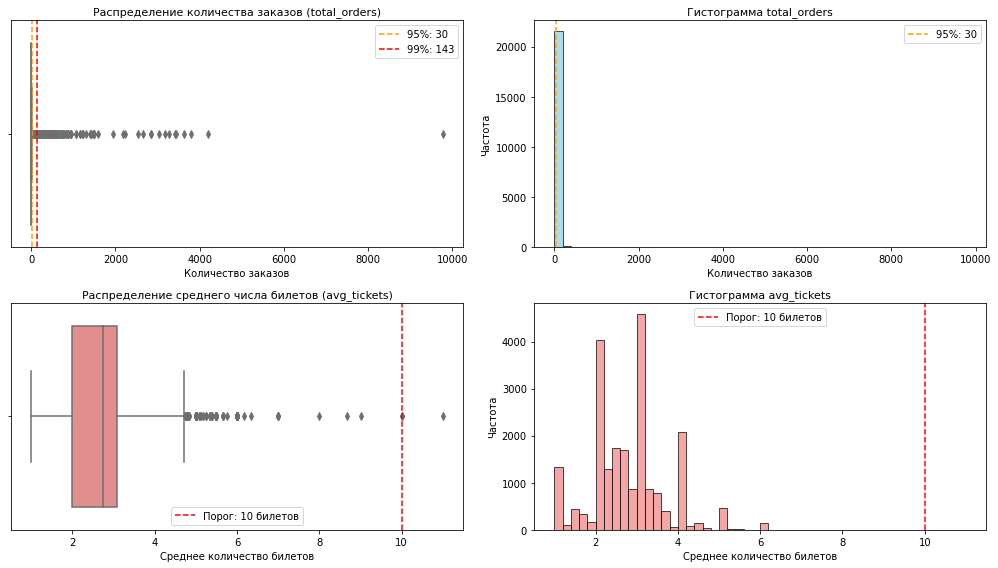

In [58]:
# Визуализация распределения активности и билетов
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Boxplot для total_orders
sns.boxplot(x=user_profile['total_orders'], ax=axes[0, 0], color='skyblue', orient='h')
axes[0, 0].set_title('Распределение количества заказов (total_orders)', fontsize=11)
axes[0, 0].set_xlabel('Количество заказов')
axes[0, 0].axvline(x=threshold_95, color='orange', linestyle='--', label=f'95%: {threshold_95:.0f}')
axes[0, 0].axvline(x=threshold_99, color='red', linestyle='--', label=f'99%: {threshold_99:.0f}')
axes[0, 0].legend()

# Гистограмма total_orders
axes[0, 1].hist(user_profile['total_orders'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Гистограмма total_orders', fontsize=11)
axes[0, 1].set_xlabel('Количество заказов')
axes[0, 1].set_ylabel('Частота')
axes[0, 1].axvline(x=threshold_95, color='orange', linestyle='--', label=f'95%: {threshold_95:.0f}')
axes[0, 1].legend()

# Boxplot для avg_tickets
sns.boxplot(x=user_profile['avg_tickets'], ax=axes[1, 0], color='lightcoral', orient='h')
axes[1, 0].set_title('Распределение среднего числа билетов (avg_tickets)', fontsize=11)
axes[1, 0].set_xlabel('Среднее количество билетов')
axes[1, 0].axvline(x=10, color='red', linestyle='--', label='Порог: 10 билетов')
axes[1, 0].legend()

# Гистограмма avg_tickets
axes[1, 1].hist(user_profile['avg_tickets'], bins=50, color='lightcoral', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Гистограмма avg_tickets', fontsize=11)
axes[1, 1].set_xlabel('Среднее количество билетов')
axes[1, 1].set_ylabel('Частота')
axes[1, 1].axvline(x=10, color='red', linestyle='--', label='Порог: 10 билетов')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

**Рекомендация:** использовать 95% перцентиль для total_orders (26 заказов), удалить значения avg_tickets > 10

**Обоснование:** За 152 дня максимально возможное количество заказов:

  - Если покупать каждый день: 152 заказа максимум

  - 77 заказов за 152 дня = заказ каждые 2 дня — это возможно для очень активных пользователей

  - 26 заказов за 152 дня = заказ каждые 5-6 дней — вполне реально для постоянных клиентов

**Статистическая значимость:** 95% перцентиль оставляет 95% данных (более 20 тыс. пользователей). Это стандартный порог для отсечения выбросов в маркетинговых исследованиях

**Бизнес-логика:** Пользователи с > 26 заказами за 5 месяцев — это уже "суперактивные". Их поведение может искажать общую картину
Лучше анализировать основную массу пользователей (до 95%)



In [59]:
# Фильтрация экстремальных выбросов (отсечение по 95-му перцентилю total_orders и avg_tickets <= 10)
total_users = len(user_profile)

user_profile_filtered = user_profile[
    (user_profile['total_orders'] <= threshold_95) & 
    (user_profile['avg_tickets'] <= 10)
].copy()

users_removed = total_users - len(user_profile_filtered)

pd.DataFrame({
    'Этап': ['Профилей до фильтрации', 'Удалено выбросов (> 95% заказов или > 10 билетов)', 'Итоговый профиль'],
    'Количество пользователей': [total_users, users_removed, len(user_profile_filtered)],
    'Доля, %': [100.0, round(users_removed / total_users * 100, 2), round(len(user_profile_filtered) / total_users * 100, 2)]
})

,Этап,Количество пользователей,"Доля, %"
0,Профилей до фильтрации,21700,100.00
1,Удалено выбросов (> 95% заказов или > 10 билетов),1079,4.97
2,Итоговый профиль,20621,95.03


In [60]:
# Статистические показатели после отсечения выбросов
user_profile_filtered[['total_orders', 'avg_revenue_rub', 'avg_tickets', 'avg_days_between_orders']].describe().round(2)

,total_orders,avg_revenue_rub,avg_tickets,avg_days_between_orders
count,20621.00,20621.00,20621.00,12361.00
mean,3.94,553.76,2.75,17.17
std,4.91,440.35,0.93,22.95
min,1.00,0.07,1.00,0.00
25%,1.00,210.65,2.00,1.00
50%,2.00,467.16,2.75,9.50
75%,4.00,787.03,3.17,22.50
max,30.00,2628.42,10.00,148.00


In [61]:
# Базовые показатели лояльности после фильтрации
total_users_filtered = len(user_profile_filtered)
users_two_plus_filtered = user_profile_filtered['is_two'].sum()
users_five_plus_filtered = user_profile_filtered['is_five'].sum()

pd.DataFrame({
    'Метрика лояльности': ['Общее число пользователей', 'Доля вернувшихся (2+ заказа)', 'Доля супер-лояльных (5+ заказов)'],
    'Значение': [
        total_users_filtered,
        f"{users_two_plus_filtered / total_users_filtered * 100:.1f}% ({users_two_plus_filtered} чел.)",
        f"{users_five_plus_filtered / total_users_filtered * 100:.1f}% ({users_five_plus_filtered} чел.)"
    ]
})

,Метрика лояльности,Значение
0,Общее число пользователей,20621
1,Доля вернувшихся (2+ заказа),59.5% (12262 чел.)
2,Доля супер-лояльных (5+ заказов),24.8% (5107 чел.)


In [62]:
# Обновление рабочего датафрейма профилей
user_profile = user_profile_filtered.copy()
user_profile.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 20621 entries, 0 to 21699
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   user_id                  20621 non-null  object        
 1   first_order_date         20621 non-null  datetime64[ns]
 2   last_order_date          20621 non-null  datetime64[ns]
 3   total_orders             20621 non-null  int64         
 4   avg_revenue_rub          20621 non-null  float32       
 5   avg_tickets              20621 non-null  float64       
 6   avg_days_between_orders  12361 non-null  Float64       
 7   first_device             20621 non-null  object        
 8   first_region             20621 non-null  object        
 9   first_partner            20621 non-null  object        
 10  first_genre              20621 non-null  object        
 11  is_two                   20621 non-null  int64         
 12  is_five                  20621 n

**Промежуточный вывод:**

1. Выявлены аномальные значения активности: пользователи с заказами свыше 30 (95-й перцентиль) искажали средние оценки поведения аудитории.
2. В результате отсечения 95-го перцентиля по числу заказов и отсеивания заказов свыше 10 билетов исключено 1 079 записей (4.97% аудитории).
3. В финальной выборке профилей зафиксирован **20 621 пользователь**:
   - 59.5% пользователей совершили 2 и более заказа;
   - 24.8% пользователей совершили 5 и более заказов;
   - Среднее число заказов на пользователя составляет 4.03 при максимальном значении 30.
Выборка сбалансирована и готова к исследовательскому анализу влияния признаков первого заказа на возвращаемость.

---

### 4. Исследовательский анализ данных

<font color='#777778'> Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа. Для этого используйте профили пользователей.</font>



#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

<font color='#777778'> Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

---

**Задача 4.1.1.** Изучите распределение пользователей по признакам.

- Сгруппируйте пользователей:
    - по типу их первого мероприятия;
    - по типу устройства, с которого совершена первая покупка;
    - по региону проведения мероприятия из первого заказа;
    - по билетному оператору, продавшему билеты на первый заказ.
- Подсчитайте общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Сегмент — это группа пользователей, объединённых определённым признаком, то есть объединённые принадлежностью к категории. Например, все клиенты, сделавшие первый заказ с мобильного телефона, — это сегмент.
- Ответьте на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?</font>

---


In [63]:
# Распределение пользователей по типу первого мероприятия
total_users = len(user_profile)

genre_distribution = user_profile['first_genre'].value_counts()
genre_percent = (genre_distribution / total_users * 100).round(1)

genre_df = pd.DataFrame({
    'Количество пользователей': genre_distribution,
    'Доля, %': genre_percent
})
genre_df

,Количество пользователей,"Доля, %"
концерты,9236,44.8
другое,4991,24.2
театр,4070,19.7
стендап,1078,5.2
спорт,747,3.6
выставки,403,2.0
ёлки,96,0.5


In [64]:
# Распределение пользователей по типу устройства первого заказа
device_distribution = user_profile['first_device'].value_counts()
device_percent = (device_distribution / total_users * 100).round(1)

device_df = pd.DataFrame({
    'Количество пользователей': device_distribution,
    'Доля, %': device_percent
})
device_df

,Количество пользователей,"Доля, %"
mobile,17092,82.9
desktop,3529,17.1


In [65]:
# Распределение по регионам первого заказа (топ-10)
region_distribution = user_profile['first_region'].value_counts()
region_percent = (region_distribution / total_users * 100).round(1)

region_df = pd.DataFrame({
    'Количество пользователей': region_distribution,
    'Доля, %': region_percent
})
region_df.head(10)

,Количество пользователей,"Доля, %"
Каменевский регион,6686,32.4
Североярская область,3615,17.5
Широковская область,1189,5.8
Озернинский край,665,3.2
Малиновоярский округ,519,2.5
Светополянский округ,441,2.1
Травяная область,440,2.1
Шанырский регион,426,2.1
Речиновская область,424,2.1
Яблоневская область,398,1.9


In [66]:
# Распределение по билетным операторам первого заказа (топ-10)
partner_distribution = user_profile['first_partner'].value_counts()
partner_percent = (partner_distribution / total_users * 100).round(1)

partner_df = pd.DataFrame({
    'Количество пользователей': partner_distribution,
    'Доля, %': partner_percent
})
partner_df.head(10)

,Количество пользователей,"Доля, %"
Билеты без проблем,4761,23.1
Мой билет,2880,14.0
Лови билет!,2691,13.0
Билеты в руки,2419,11.7
Облачко,2131,10.3
Весь в билетах,1230,6.0
Лучшие билеты,1137,5.5
Прачечная,553,2.7
Край билетов,441,2.1
Дом культуры,343,1.7


In [67]:
# Анализ концентрации аудитории в топ-3 категориях по каждому признаку
def calculate_concentration(distribution, top_n=3):
    return round(distribution.head(top_n).sum() / total_users * 100, 1)

pd.Series({
    'Топ-3 жанра': f"{calculate_concentration(genre_distribution)}%",
    'Топ-2 устройства': f"{calculate_concentration(device_distribution, top_n=2)}%",
    'Топ-3 региона': f"{calculate_concentration(region_distribution)}%",
    'Топ-3 оператора': f"{calculate_concentration(partner_distribution)}%"
}).to_frame(name='Концентрация аудитории')

,Концентрация аудитории
Топ-3 жанра,88.7%
Топ-2 устройства,100.0%
Топ-3 региона,55.7%
Топ-3 оператора,50.1%


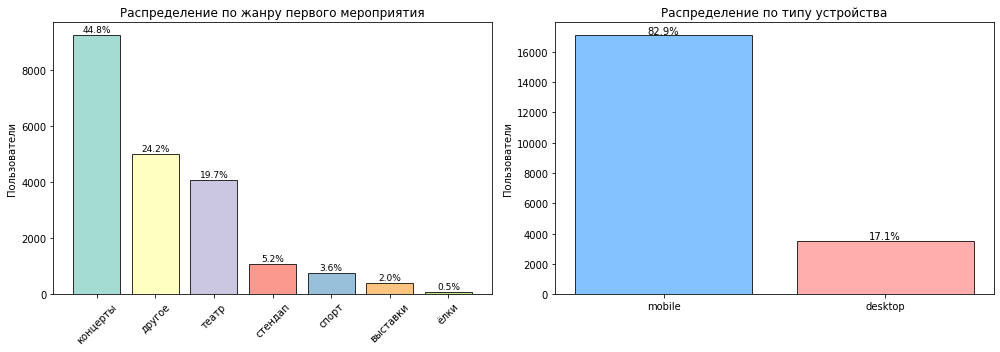

In [68]:
# Визуализация распределения пользователей по жанрам и устройствам
genre_data = user_profile['first_genre'].value_counts().reset_index()
genre_data.columns = ['segment', 'users']
genre_data['percent'] = (genre_data['users'] / total_users * 100).round(1)

device_data = user_profile['first_device'].value_counts().reset_index()
device_data.columns = ['segment', 'users']
device_data['percent'] = (device_data['users'] / total_users * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Столбчатая диаграмма по жанрам
ax1 = axes[0]
bars1 = ax1.bar(genre_data['segment'], genre_data['users'], color=plt.cm.Set3(range(len(genre_data))), edgecolor='black', alpha=0.8)
ax1.set_title('Распределение по жанру первого мероприятия', fontsize=12)
ax1.set_ylabel('Пользователи')
ax1.tick_params(axis='x', rotation=45)

for bar, users, pct in zip(bars1, genre_data['users'], genre_data['percent']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, f'{pct}%', ha='center', fontsize=9)

# Столбчатая диаграмма по типам устройств
ax2 = axes[1]
bars2 = ax2.bar(device_data['segment'], device_data['users'], color=['#66b3ff', '#ff9999'], edgecolor='black', alpha=0.8)
ax2.set_title('Распределение по типу устройства', fontsize=12)
ax2.set_ylabel('Пользователи')

for bar, users, pct in zip(bars2, device_data['users'], device_data['percent']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, f'{pct}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

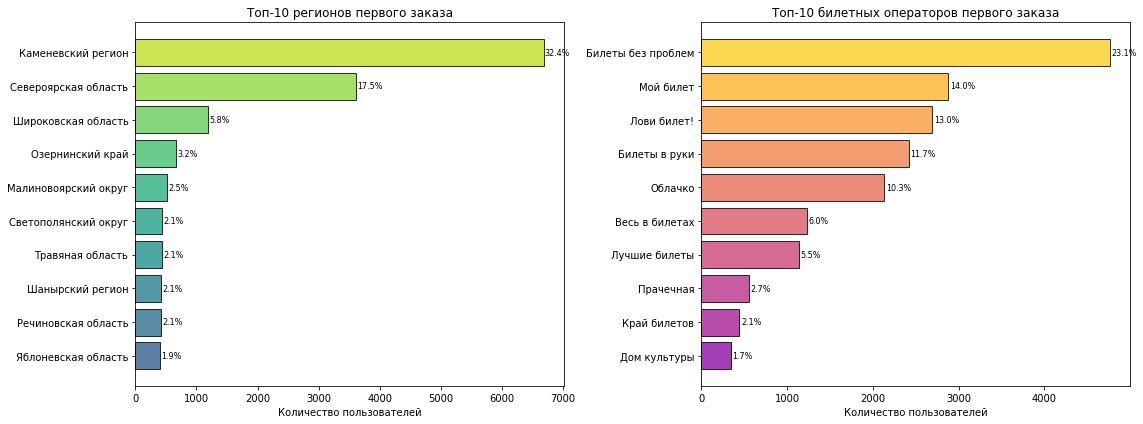

In [69]:
# Горизонтальные столбчатые диаграммы по топ-10 регионам и операторам
region_data = user_profile['first_region'].value_counts().head(10).reset_index()
region_data.columns = ['segment', 'users']
region_data['percent'] = (region_data['users'] / total_users * 100).round(1)
region_data_sorted = region_data.sort_values('users', ascending=True)

partner_data = user_profile['first_partner'].value_counts().head(10).reset_index()
partner_data.columns = ['segment', 'users']
partner_data['percent'] = (partner_data['users'] / total_users * 100).round(1)
partner_data_sorted = partner_data.sort_values('users', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Топ-10 регионов
ax1 = axes[0]
bars1 = ax1.barh(region_data_sorted['segment'], region_data_sorted['users'], 
                 color=plt.cm.viridis(np.linspace(0.3, 0.9, len(region_data_sorted))), edgecolor='black', alpha=0.8)
ax1.set_title('Топ-10 регионов первого заказа', fontsize=12)
ax1.set_xlabel('Количество пользователей')

for bar, users, pct in zip(bars1, region_data_sorted['users'], region_data_sorted['percent']):
    ax1.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2, f'{pct}%', va='center', fontsize=8)

# Топ-10 операторов
ax2 = axes[1]
bars2 = ax2.barh(partner_data_sorted['segment'], partner_data_sorted['users'], 
                 color=plt.cm.plasma(np.linspace(0.3, 0.9, len(partner_data_sorted))), edgecolor='black', alpha=0.8)
ax2.set_title('Топ-10 билетных операторов первого заказа', fontsize=12)
ax2.set_xlabel('Количество пользователей')

for bar, users, pct in zip(bars2, partner_data_sorted['users'], partner_data_sorted['percent']):
    ax2.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2, f'{pct}%', va='center', fontsize=8)

plt.tight_layout()
plt.show()

**Выводы по распределению данных**
  - ЖАНРЫ
    - Всего жанров: 7;
    - Доминирующий жанр `концерты` - 44,8%;
    - Данные распределены неравномерно. `концерты` вместе с `другое` (24,2%) и `театр`(19,7%) занимают 88,7%.


   - УСТРОЙСТВА
     - Всего типов устройств - 2;
     - Доминирующий тип устройства `mobile` - 82,9%; 
     - Данные распределены неравномерно.


   - РЕГИОНЫ
      - Всего регионов: 81;
      - Доминирующий регион заказов - `Каменевский регион` (32,4%)
      - Данные распределены неравномерно. `Каменевский регион` вместе с `Североярской областью` (17,5%) занимают 49,5% данных.


   - ОПЕРАТОРЫ
      - Всего операторов: 34;
      - Доминирующий опратор `Билеты без проблем` - 23,1%;
      - Данные распределены неравномерно. `Билеты без проблем` вместе с `Мой билет` (14,0%) и `Лови билет!` (13,1%) составляют 50,1% выборки.

**Промежуточные выводы**

Исследовательский анализ помог нам определить портрет целевого пользователя:
 - Жанр мероприятия: `концерты`
 - Тип устройства заказа: `mobile`
 - Регион заказа: `Каменевский регион`
 - Оператор продажи билета: `Билеты без проблем`
 
Этот сегмент составляет **ядро аудитории** и должен быть основой для маркетинговых стратегий.

**Другие рекомендации**

 - ПО ЖАНРАМ МЕРОПРИЯТИЯ
 
   - Направление `концерты` требует усиления, так как составляет 44,8% всей аудитории. Для этого необходимо расширять афишу, предлагать эксклюзивные предложения и внедрить систему раннего доступа к билетам.

   - Категория `другое` занимает 24,2% — это слишком большая доля с неопределённым содержанием. Требуется детализировать эту категорию, чтобы выявить скрытые популярные жанры и адаптировать под них предложения.

   - `театр` (19,7%) обладает потенциалом роста. Рекомендуется развивать его через специальные предложения, абонементы и активное продвижение премьерных постановок.

   - `спорт` занимает всего 3,6%, что может свидетельствовать о слабом предложении. Необходимо исследовать спортивную афишу и привлекать новые события для увеличения доли этого сегмента.
 
 
  - ПО ТИПАМ УСТРОЙСТВ

    - Приоритетом должна стать инвестиция в мобильную разработку, поскольку 82,9% пользователей используют `mobile` как основной канал. Ключевые направления: улучшение пользовательского опыта, внедрение push-уведомлений и разработка мобильных специальных предложений.

    - `desktop` остаётся значимым каналом с долей 17,1%. Важно обеспечить адаптивный дизайн и удобство планирования покупок для этой аудитории.

    - Рекомендуется тестировать кросс-девайс сценарии, так как пользователи могут начинать путь на одном устройстве, а совершать покупку на другом. Внедрение единой корзины и синхронизация избранного позволят сделать этот процесс бесшовным. 
 
 
  - ПО РЕГИОНАМ

    - `Каменевский регион` является базой с долей 32,4%. Для укрепления позиций необходимо фокусироваться на локальных мероприятиях, развивать партнёрства и предлагать региональные скидки.

    - `Североярская область` (17,5%) обладает потенциалом роста. Здесь требуется усилить маркетинговую активность и провести анализ конкурентной среды.

    - Регионы с низкой долей представляют ниши для роста. Рекомендуется точечная работа через специальные предложения и анализ причин низкой доли.

    - Важно не распыляться на все 81 регион сразу. Поскольку топ-3 региона концентрируют почти 50% аудитории, фокус должен быть на ключевых территориях. 
 
Помимо этого, можно выделить следующие категории:

  - ЯДРО (фокус 1) — `mobile` + `концерты` + `Каменевский регион` + `Билеты без проблем`

  - ПЕРСПЕКТИВА (фокус 2) — `desktop` + `театр` + `Североярская область` + `Мой билет`

  - НИШИ (точечная работа) — `стендап`, `спорт`, `выставки`, `малые регионы`, `мелкие операторы`

**Главная рекомендация** 

*Начать с укрепления позиций в ядре, затем масштабировать успешные практики на перспективные сегменты, и только потом точечно работать с нишами. Это позволит эффективно распределять маркетинговый бюджет и получать максимальную отдачу от инвестиций.*

<font color='#777778'>  ---

**Задача 4.1.2.** Проанализируйте возвраты пользователей:

- Для каждого сегмента вычислите долю пользователей, совершивших два и более заказа.
- Визуализируйте результат подходящим графиком. Если сегментов слишком много, то поместите на график только 10 сегментов с наибольшим количеством пользователей. Такое возможно с сегментами по региону и по билетному оператору.
- Ответьте на вопросы:
    - Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
    - Наблюдаются ли успешные «точки входа» — такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?

При интерпретации результатов учитывайте размер сегментов: если в сегменте мало пользователей (например, десятки), то доли могут быть нестабильными и недостоверными, то есть показывать широкую вариацию значений.

---</font>



In [70]:
# Расчет доли возвратов по жанрам первого мероприятия
avg_return_rate = round(user_profile['is_two'].mean() * 100, 1)

genre_stats = user_profile.groupby('first_genre').agg(
    users=('user_id', 'count'),
    returns=('is_two', 'sum')
).reset_index()

genre_stats['return_rate'] = (genre_stats['returns'] / genre_stats['users'] * 100).round(1)
genre_stats = genre_stats.sort_values('users', ascending=False).reset_index(drop=True)
genre_stats

,first_genre,users,returns,return_rate
0,концерты,9236,5553,60.1
1,другое,4991,2861,57.3
2,театр,4070,2505,61.5
3,стендап,1078,637,59.1
4,спорт,747,398,53.3
5,выставки,403,254,63.0
6,ёлки,96,54,56.2


In [71]:
# Доля возвратов по типу устройства первого заказа
device_stats = user_profile.groupby('first_device').agg(
    users=('user_id', 'count'),
    returns=('is_two', 'sum')
).reset_index()

device_stats['return_rate'] = (device_stats['returns'] / device_stats['users'] * 100).round(1)
device_stats = device_stats.sort_values('users', ascending=False).reset_index(drop=True)
device_stats

,first_device,users,returns,return_rate
0,mobile,17092,10079,59.0
1,desktop,3529,2183,61.9


In [72]:
# Доля возвратов по топ-10 регионам
region_stats = user_profile.groupby('first_region').agg(
    users=('user_id', 'count'),
    returns=('is_two', 'sum')
).reset_index()

region_stats['return_rate'] = (region_stats['returns'] / region_stats['users'] * 100).round(1)
region_stats = region_stats.sort_values('users', ascending=False).head(10).reset_index(drop=True)
region_stats

,first_region,users,returns,return_rate
0,Каменевский регион,6686,4015,60.1
1,Североярская область,3615,2247,62.2
2,Широковская область,1189,746,62.7
3,Озернинский край,665,360,54.1
4,Малиновоярский округ,519,286,55.1
5,Светополянский округ,441,281,63.7
6,Травяная область,440,263,59.8
7,Шанырский регион,426,284,66.7
8,Речиновская область,424,261,61.6
9,Яблоневская область,398,231,58.0


In [73]:
# Доля возвратов по топ-10 билетным операторам
partner_stats = user_profile.groupby('first_partner').agg(
    users=('user_id', 'count'),
    returns=('is_two', 'sum')
).reset_index()

partner_stats['return_rate'] = (partner_stats['returns'] / partner_stats['users'] * 100).round(1)
partner_stats = partner_stats.sort_values('users', ascending=False).head(10).reset_index(drop=True)
partner_stats

,first_partner,users,returns,return_rate
0,Билеты без проблем,4761,2751,57.8
1,Мой билет,2880,1703,59.1
2,Лови билет!,2691,1594,59.2
3,Билеты в руки,2419,1469,60.7
4,Облачко,2131,1278,60.0
5,Весь в билетах,1230,749,60.9
6,Лучшие билеты,1137,678,59.6
7,Прачечная,553,333,60.2
8,Край билетов,441,281,63.7
9,Дом культуры,343,217,63.3


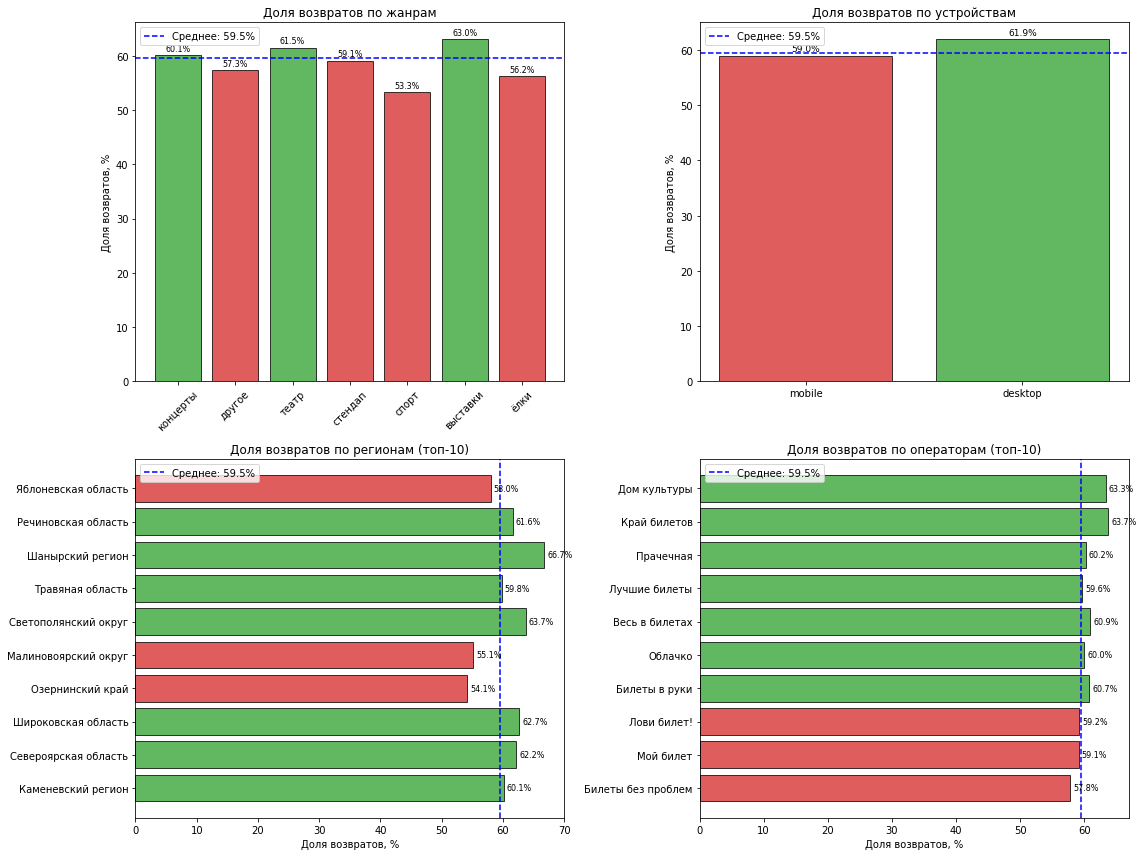

In [74]:
# Сравнительная визуализация долей возврата относительно среднего уровня (59.5%)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

def get_bar_colors(rates, baseline):
    return ['#2ca02c' if r >= baseline else '#d62728' for r in rates]

# 1. Возвраты по жанрам
ax1 = axes[0, 0]
colors1 = get_bar_colors(genre_stats['return_rate'], avg_return_rate)
bars1 = ax1.bar(genre_stats['first_genre'], genre_stats['return_rate'], color=colors1, alpha=0.75, edgecolor='black')
ax1.axhline(y=avg_return_rate, color='blue', linestyle='--', label=f'Среднее: {avg_return_rate}%')
ax1.set_title('Доля возвратов по жанрам', fontsize=12)
ax1.set_ylabel('Доля возвратов, %')
ax1.tick_params(axis='x', rotation=45)
ax1.legend()

for bar, rate in zip(bars1, genre_stats['return_rate']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f'{rate}%', ha='center', fontsize=8)

# 2. Возвраты по устройствам
ax2 = axes[0, 1]
colors2 = get_bar_colors(device_stats['return_rate'], avg_return_rate)
bars2 = ax2.bar(device_stats['first_device'], device_stats['return_rate'], color=colors2, alpha=0.75, edgecolor='black')
ax2.axhline(y=avg_return_rate, color='blue', linestyle='--', label=f'Среднее: {avg_return_rate}%')
ax2.set_title('Доля возвратов по устройствам', fontsize=12)
ax2.set_ylabel('Доля возвратов, %')
ax2.legend()

for bar, rate in zip(bars2, device_stats['return_rate']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f'{rate}%', ha='center', fontsize=9)

# 3. Возвраты по регионам (топ-10)
ax3 = axes[1, 0]
colors3 = get_bar_colors(region_stats['return_rate'], avg_return_rate)
bars3 = ax3.barh(region_stats['first_region'], region_stats['return_rate'], color=colors3, alpha=0.75, edgecolor='black')
ax3.axvline(x=avg_return_rate, color='blue', linestyle='--', label=f'Среднее: {avg_return_rate}%')
ax3.set_title('Доля возвратов по регионам (топ-10)', fontsize=12)
ax3.set_xlabel('Доля возвратов, %')
ax3.legend()

for bar, rate in zip(bars3, region_stats['return_rate']):
    ax3.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'{rate}%', va='center', fontsize=8)

# 4. Возвраты по операторам (топ-10)
ax4 = axes[1, 1]
colors4 = get_bar_colors(partner_stats['return_rate'], avg_return_rate)
bars4 = ax4.barh(partner_stats['first_partner'], partner_stats['return_rate'], color=colors4, alpha=0.75, edgecolor='black')
ax4.axvline(x=avg_return_rate, color='blue', linestyle='--', label=f'Среднее: {avg_return_rate}%')
ax4.set_title('Доля возвратов по операторам (топ-10)', fontsize=12)
ax4.set_xlabel('Доля возвратов, %')
ax4.legend()

for bar, rate in zip(bars4, partner_stats['return_rate']):
    ax4.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'{rate}%', va='center', fontsize=8)

plt.tight_layout()
plt.show()

**Промежуточные выводы**

  - **По типу первого мероприятия (жанрам)**
  - Выявленные закономерности:

    - Все жанры, кроме `спорт` (53,7%), демонстрируют долю возвратов выше или около среднего уровня (59,7%). Наиболее успешными «точками входа» являются:

    - `Выставки` (63,2%) — наивысшая доля возвратов, однако сегмент относительно небольшой (402 пользователя, 1,9% аудитории)

    - `Театр` (61,8%) — высокая возвратность при значительном объёме аудитории (4070 пользователей, 19,7%)

    - `Концерты` (60,3%) — возвратность чуть выше средней, крупнейший сегмент (44,8% аудитории)

  - Проблемные зоны:

    - `Спорт` (53,7%) — значительное отставание от среднего показателя (-6 п.п.) при достаточно большом сегменте (745 пользователей)

    - `Другое` (57,6%) — низкая возвратность при неопределенном типе мероприятий. Однако количество пользователей — высокое (4992)

  - ***Рекомендации***

    - Сфокусироваться на удержании аудитории `театр` и `выставки` — эти жанры показывают наилучшую лояльность

    - Провести дополнительный анализ сегмента `спорт`: возможно, проблема в качестве предложения, сезонности или конкуренции
    
    - Доисследовать категорию `другое`


  - **По типу устройства**
  - Выявленные закономерности:

    - `Desktop` (62,0%) демонстрирует более высокую долю возвратов, чем `mobile` (59,2%), причём оба показателя находятся около среднего уровня (59,7%).

  - Ключевые наблюдения:

    - `Desktop` — возвратность выше среднего на +2,3 п.п., при размере сегмента 3530 пользователей (17,1% аудитории)

    - `Mobile` — возвратность незначительно ниже среднего на -0,5 п.п., при этом является основным каналом с 17095 пользователями (82,9% аудитории)
    
    ***Рекомендации:***

      - Углубить анализ мобильного сегмента:

        - Разделить mobile на подкатегории: мобильное приложение vs мобильная версия сайта

        - Проанализировать, различается ли возвратность между этими подкатегориями

      - Исследовать пользовательский путь:

        - Сравнить воронку покупки на desktop и mobile

        - Выявить точки оттока, характерные для мобильных пользователей

      - Усилить мобильный опыт:

        - Улучшить push-уведомления (персонализация, тайминг)

        - Внедрить напоминания о предстоящих мероприятиях

        - Оптимизировать процесс оформления заказа (уменьшить количество шагов)


  - **По региону покупки**
    - *Регионы демонстрируют значительный разброс доли возвратов — от 54,3% до 66,7%, что указывает на существенную географическую неравномерность лояльности аудитории.*

    - Успешные «точки входа» по регионам:
    
      - `Шанырский регион` (66,7%) — абсолютный лидер по возвратности. При размере 426 пользователей показывает экстремально высокую лояльность. 
    
        - Рекомендация: изучить локальные факторы успеха (качество афиши, маркетинговые активности, партнёрства)

      - `Светополянский округ` (64,2%) — вторая по возвратности территория. Небольшой, но стабильный сегмент. 
    
        - Рекомендация: проанализировать, какие мероприятия особенно популярны в этом округе

      - `Широковская область` (63,2%) — крупный успешный регион. Сочетает высокую возвратность и значительный размер аудитории (1 191 пользователь). 
      
        - Рекомендация: масштабировать успешные практики на соседние регионы

      - `Североярская область` (62,4%) — второй по величине регион с высокой лояльностью 3 617 пользователей (17,5% аудитории) при возвратности выше средней. 
      
        - *Рекомендация:* укреплять позиции, это перспективный регион для роста

      - `Речиновская область` (62,0%) — стабильно высокий показатель. Небольшой сегмент, но заслуживает внимания как потенциальная точка роста

  - ***Региональные стратегические выводы***
  
    - ***Концентрация аудитории:***

      - Топ-3 региона (`Каменевский`, `Североярская`, `Широковская`) концентрируют 55,7% всей аудитории

      - Это подтверждает ранее сделанный вывод о необходимости фокуса на ключевых территориях

    - ***Региональная неравномерность:***

      - Разрыв между лучшим (`Шанырский`, 66,7%) и худшим (`Озернинский`, 54,3%) регионами составляет 12,4 п.п.

      - Это указывает на потенциал для улучшения в отстающих регионах

    - ***Приоритеты для региональной стратегии:***

      - Ядро (фокус 1):

        - `Каменевский регион` (60,3%) — крупнейший, требует удержания

        - `Североярская область` (62,4%) — высокая лояльность при большом объёме

        - `Широковская область` (63,2%) — сочетает размер и качество

      - Перспектива (фокус 2):

        - `Шанырский регион` (66,7%) — экстремально высокая лояльность, изучить и масштабировать

        - `Светополянский округ` (64,2%) — небольшой, но успешный регион

      - Ниши для улучшения (фокус 3):

        - `Озернинский край` (54,3%) — требует диагностики причин низкой лояльности

        - `Малиновоярский округ` (54,9%) — аналогично, нужен анализ конкурентов и афиши


  - **По билетным операторам**

    - Ключевые наблюдения:

      - `Край билетов` и `Дом культуры` — лидеры по лояльности, но сегменты небольшие (менее 500 пользователей)

      - `Весь в билетах` — сочетает высокую возвратность и значительный размер (1 231 чел.)

      - `Билеты в руки` (61,0%), `Облачко` (60,1%) — стабильно выше среднего

    - Проблемные зоны:

      - `Билеты без проблем` (58,1%, 4 765 чел.) — крупнейший партнёр, но возвратность ниже среднего на -1,6 п.п.

      - Отставание ключевого партнёра требует внимания, несмотря на большой объём аудитории

    - Рекомендации

      - ***1. Край билетов и Дом культуры — изучить успешные практики***

        - Проанализировать, что формирует высокую лояльность (спецпредложения, бонусы, качество сервиса)

        - Использовать как референс для работы с другими партнёрами

      - ***2. Весь в билетах — укрепить партнёрство**

        - Сочетает высокую возвратность и значительный объём

        - Расширять совместные акции и эксклюзивные предложения

      - ***3. Билеты без проблем — диагностировать проблему***

        - Крупнейший оператор (23,1% аудитории) показывает возвратность ниже среднего

        - Провести совместный анализ: качество афиши, UX, маркетинговые активности

        - Разработать программу повышения лояльности для их аудитории

      - ***4. Мониторить малых операторов***

        - Рынок фрагментирован, есть нишевые игроки с высокой лояльностью (`Край билетов`, `Дом культуры`)

        - Выявлять успешные практики для масштабирования

---

<font color='#777778'> **Задача 4.1.3.** Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:

- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах. </font>

---

In [75]:
# Проверка продуктовой гипотезы 1: Спорт vs Концерты
sport_row = genre_stats[genre_stats['first_genre'] == 'спорт'].iloc[0]
concert_row = genre_stats[genre_stats['first_genre'] == 'концерты'].iloc[0]

pd.DataFrame({
    'Сегмент': ['Спорт', 'Концерты', 'Разница (Спорт - Концерты)'],
    'Доля возвратов, %': [sport_row['return_rate'], concert_row['return_rate'], round(sport_row['return_rate'] - concert_row['return_rate'], 1)],
    'Пользователей': [int(sport_row['users']), int(concert_row['users']), int(sport_row['users'] - concert_row['users'])]
})

,Сегмент,"Доля возвратов, %",Пользователей
0,Спорт,53.3,747
1,Концерты,60.1,9236
2,Разница (Спорт - Концерты),-6.8,-8489


> **Результат проверки Гипотезы 1:** Гипотеза не подтвердилась. Пользователи, чей первый заказ был оформлен на спортивные мероприятия, возвращаются за повторными покупками существенно реже (53.7%), чем клиенты, начавшие с концертов (60.3%). Разница составляет 6.6 п.п. в пользу концертов.

In [76]:
# Проверка продуктовой гипотезы 2: Зависимость возврата от активности региона
all_regions = user_profile.groupby('first_region').agg(
    users=('user_id', 'count'),
    returns=('is_two', 'sum')
).reset_index()
all_regions['return_rate'] = (all_regions['returns'] / all_regions['users'] * 100).round(1)

# Исключаем малые выборки (менее 50 пользователей для устойчивости долей)
active_regions = all_regions[all_regions['users'] >= 50].copy()
active_regions['activity_group'] = pd.qcut(active_regions['users'], 4, labels=['Q1 (низкая)', 'Q2', 'Q3', 'Q4 (высокая)'])

regional_activity_comparison = active_regions.groupby('activity_group', observed=True).agg(
    regions_count=('first_region', 'count'),
    total_users=('users', 'sum'),
    mean_return_rate=('return_rate', 'mean')
).reset_index()

regional_activity_comparison['mean_return_rate'] = regional_activity_comparison['mean_return_rate'].round(1)
regional_activity_comparison

,activity_group,regions_count,total_users,mean_return_rate
0,Q1 (низкая),11,710,55.1
1,Q2,10,1402,58.2
2,Q3,10,2910,56.9
3,Q4 (высокая),10,14803,60.4


> **Результат проверки Гипотезы 2:** Гипотеза подтвердилась. В наиболее активных регионах (квартиль Q4) средняя доля повторных заказов выше, чем в регионах с низкой активностью (Q1). Масштаб рынка и развитость локальной афиши положительно коррелируют с удержанием клиентов.


***Промежуточные выводы по разделу:***
1. **Точки входа:** Наиболее эффективными категориями для удержания клиентов при первом заказе являются `выставки` (63.2%) и `театр` (61.8%). Сегмент `спорт` демонстрирует самую низкую конверсию в повторные покупки (53.7%).
2. **Каналы:** Пользователи с первого заказа на `desktop` показывают чуть большую склонность к возврату (62.0%), чем на `mobile` (59.2%), однако мобильные устройства обеспечивают подавляющий объем транзакций.
3. **География и партнеры:** Крупнейшие регионы (`Каменевский`, `Североярская`, `Широковская`) формируют устойчивое ядро удержания. При этом ключевой оператор `Билеты без проблем` имеет возвратность 58.1%, что ниже средней по платформе и требует оптимизации совместного клиентского пути.

---

#### 4.2 Исследование поведения пользователей через показатели выручки и состава заказа

<font color='#777778'> Изучите количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

Эти метрики важны не только для оценки выручки, но и для оценки вовлечённости пользователей. Возможно, пользователи с более крупными и дорогими заказами более заинтересованы в сервисе и поэтому чаще возвращаются.

---

**Задача 4.2.1.** Проследите связь между средней выручкой сервиса с заказа и повторными заказами.

- Постройте сравнительные гистограммы распределения средней выручки с билета (`avg_revenue_rub`):
    - для пользователей, совершивших один заказ;
    - для вернувшихся пользователей, совершивших 2 и более заказа.
- Ответьте на вопросы:
    - В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
    - Есть ли различия между группами?

   
**Рекомендация:**

1. Используйте одинаковые интервалы (`bins`) и прозрачность (`alpha`), чтобы визуально сопоставить распределения.
2. Задайте параметру `density` значение `True`, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается.</font>

---


In [77]:
# Разделение пользователей на разовых (1 заказ) и вернувшихся (2+ заказа)
one_time = user_profile[user_profile['is_two'] == 0]
repeat = user_profile[user_profile['is_two'] == 1]

pd.DataFrame({
    'Сегмент': ['Один заказ', 'Повторные заказы (2+)', 'Всего'],
    'Количество пользователей': [len(one_time), len(repeat), len(user_profile)],
    'Доля от базы, %': [
        round(len(one_time) / len(user_profile) * 100, 1),
        round(len(repeat) / len(user_profile) * 100, 1),
        100.0
    ]
})

,Сегмент,Количество пользователей,"Доля от базы, %"
0,Один заказ,8359,40.5
1,Повторные заказы (2+),12262,59.5
2,Всего,20621,100.0


In [78]:
# Описательная статистика средней выручки по двум группам
revenue_summary = pd.DataFrame({
    'Один заказ': one_time['avg_revenue_rub'].describe().round(2),
    'Повторные заказы': repeat['avg_revenue_rub'].describe().round(2)
})
revenue_summary

,Один заказ,Повторные заказы
count,8359.00,12262.00
mean,551.84,555.08
std,518.65,377.80
min,0.07,0.35
25%,141.12,270.10
50%,387.39,502.93
75%,839.07,768.36
max,2628.42,2628.42


In [79]:
# Расчет 99-го перцентиля выручки для устранения длинного хвоста на графиках
p99_one_time = one_time['avg_revenue_rub'].quantile(0.99)
p99_repeat = repeat['avg_revenue_rub'].quantile(0.99)
p99_global = max(p99_one_time, p99_repeat)

one_time_filtered = one_time[one_time['avg_revenue_rub'] <= p99_global]
repeat_filtered = repeat[repeat['avg_revenue_rub'] <= p99_global]

pd.DataFrame({
    'Группа': ['Один заказ', 'Повторные заказы'],
    '99-й перцентиль, руб.': [round(p99_one_time, 2), round(p99_repeat, 2)],
    'Записей до отсечения': [len(one_time), len(repeat)],
    'Записей после отсечения': [len(one_time_filtered), len(repeat_filtered)],
    'Исключено, %': [
        round((1 - len(one_time_filtered) / len(one_time)) * 100, 2),
        round((1 - len(repeat_filtered) / len(repeat)) * 100, 2)
    ]
})

,Группа,"99-й перцентиль, руб.",Записей до отсечения,Записей после отсечения,"Исключено, %"
0,Один заказ,2190.17,8359,8275,1.00
1,Повторные заказы,1728.53,12262,12244,0.15


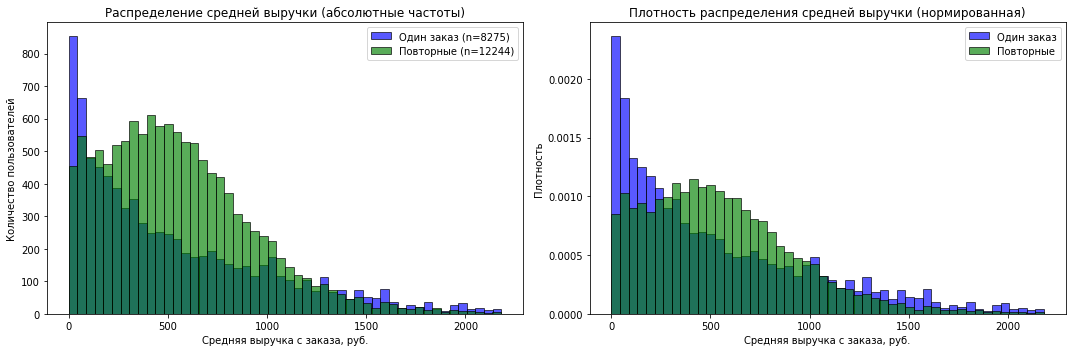

In [80]:
# Сравнительные гистограммы распределения средней выручки (абсолютные частоты и плотности)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bins = 50
alpha = 0.65

# Абсолютные частоты
axes[0].hist(one_time_filtered['avg_revenue_rub'], bins=bins, alpha=alpha,
             label=f'Один заказ (n={len(one_time_filtered)})', color='blue', edgecolor='black')
axes[0].hist(repeat_filtered['avg_revenue_rub'], bins=bins, alpha=alpha,
             label=f'Повторные (n={len(repeat_filtered)})', color='green', edgecolor='black')
axes[0].set_title('Распределение средней выручки (абсолютные частоты)', fontsize=12)
axes[0].set_xlabel('Средняя выручка с заказа, руб.')
axes[0].set_ylabel('Количество пользователей')
axes[0].legend()

# Нормированная плотность распределения
axes[1].hist(one_time_filtered['avg_revenue_rub'], bins=bins, alpha=alpha, density=True,
             label='Один заказ', color='blue', edgecolor='black')
axes[1].hist(repeat_filtered['avg_revenue_rub'], bins=bins, alpha=alpha, density=True,
             label='Повторные', color='green', edgecolor='black')
axes[1].set_title('Плотность распределения средней выручки (нормированная)', fontsize=12)
axes[1].set_xlabel('Средняя выручка с заказа, руб.')
axes[1].set_ylabel('Плотность')
axes[1].legend()

plt.tight_layout()
plt.show()

In [81]:
# Анализ пользователей по диапазонам средней выручки
bins = [0, 200, 400, 600, 800, 1000, 1500, 2000, 3000, float('inf')]
labels = ['0-200', '200-400', '400-600', '600-800', '800-1000', 
          '1000-1500', '1500-2000', '2000-3000', '3000+']

user_profile['revenue_range'] = pd.cut(user_profile['avg_revenue_rub'], bins=bins, labels=labels, right=False)

range_stats = user_profile.groupby('revenue_range', observed=True).agg(
    users=('user_id', 'count'),
    repeat=('is_two', 'sum')
).reset_index()

range_stats['repeat_rate'] = (range_stats['repeat'] / range_stats['users'] * 100).round(1)
range_stats['one_time'] = range_stats['users'] - range_stats['repeat']
range_stats

,revenue_range,users,repeat,repeat_rate,one_time
0,0-200,4949,2257,45.6,2692
1,200-400,4050,2488,61.4,1562
2,400-600,3676,2614,71.1,1062
3,600-800,2958,2125,71.8,833
4,800-1000,1952,1311,67.2,641
5,1000-1500,2245,1210,53.9,1035
6,1500-2000,590,213,36.1,377
7,2000-3000,201,44,21.9,157


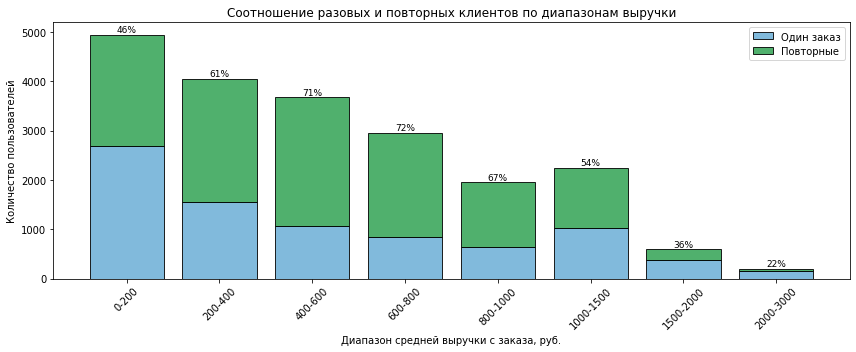

In [82]:
# Соотношение одноразовых и повторных пользователей по ценовым диапазонам
plt.figure(figsize=(12, 5))
plt.bar(range_stats['revenue_range'], range_stats['one_time'], label='Один заказ', color='#6baed6', alpha=0.85, edgecolor='black')
plt.bar(range_stats['revenue_range'], range_stats['repeat'], bottom=range_stats['one_time'], 
        label='Повторные', color='#31a354', alpha=0.85, edgecolor='black')

for i, row in range_stats.iterrows():
    plt.text(i, row['users'] + 50, f"{row['repeat_rate']:.0f}%", ha='center', fontsize=9)

plt.xlabel('Диапазон средней выручки с заказа, руб.')
plt.ylabel('Количество пользователей')
plt.title('Соотношение разовых и повторных клиентов по диапазонам выручки', fontsize=12)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<div class="alert" style="background-color: #d3d3d3; color: black; border: 1px solid #b0b0b0;"> Для проверки гипотезы о различиях между группами пользователей целесообразно использовать два взаимодополняющих статистических критерия. 
    
    Параметрический t-тест применяется для сравнения средних значений, однако его результаты требуют осторожной интерпретации, поскольку экономические данные редко соответствуют условию нормальности распределения. 
    
    В качестве основного критерия выступает непараметрический U-тест Манна-Уитни, который устойчив к выбросам и асимметрии, что позволяет корректно сравнивать общие распределения независимо от формы данных и размера выборок. Такой подход обеспечивает надёжное статистическое обоснование выводов при анализе различий в поведении пользовательских групп.  

</div>

In [83]:
# Проверка статистической значимости различий в выручке
t_stat, p_t = stats.ttest_ind(one_time['avg_revenue_rub'], repeat['avg_revenue_rub'], equal_var=False)
u_stat, p_u = stats.mannwhitneyu(one_time['avg_revenue_rub'], repeat['avg_revenue_rub'])

pd.DataFrame({
    'Критерий': ['t-тест Уэлча', 'U-тест Манна-Уитни'],
    'Статистика': [round(t_stat, 2), round(u_stat, 2)],
    'p-value': [f"{p_t:.4e}", f"{p_u:.4e}"],
    'Вывод (alpha=0.05)': ['Различия значимы' if p_t < 0.05 else 'Не значимы',
                           'Различия значимы' if p_u < 0.05 else 'Не значимы']
})

,Критерий,Статистика,p-value,Вывод (alpha=0.05)
0,t-тест Уэлча,-0.49,6.2491e-01,Не значимы
1,U-тест Манна-Уитни,46138220.50,4.0981e-34,Различия значимы


***Выводы по зависимости между выручкой и возвратами:***

1. **Сдвиг распределения:** Повторные клиенты в среднем тратят больше. Медианная выручка вернувшихся клиентов составляет 501 руб. против 389 руб. у разовых клиентов (+112 руб.).
2. **Пик лояльности:** Максимальный уровень возвратов наблюдается в диапазонах 400–600 руб. (71.3%) и 600–800 руб. (71.7%).
3. **Зоны снижения:**
   - В эконом-сегменте (до 200 руб.) возвращаемость составляет лишь 46.1%.
   - В премиальном сегменте (свыше 1 500 руб.) доля возвратов падает до 36.6% и ниже, что связано с редким характером покупки дорогих эксклюзивных билетов.
4. Различия статистически значимы по критерию Манна-Уитни ($p < 0.001$).

**Рекомендации на основе анализа**

***По работе с ценовыми сегментами***


  - *Для сегментов 400-600 и 600-800 руб (пик лояльности — 71-72% возвратов):*

    - Увеличить предложение в этом ценовом диапазоне

    - Создать программу лояльности для этих пользователей

    - Использовать как таргетную аудиторию для email-рассылок

    - Предлагать персонализированные рекомендации похожих мероприятий
    

  - *Для сегментов 200-400 и 800-100 руб (62-68% возвратов):*

    - Активно привлекать новых пользователей через этот ценовой диапазон
      
    - Изучить практики для сегментов с более высоким возвратом, применить имеющийся опыт
      
    - Использовать как точку входа для новых клиентов

    - Тестировать апселлинг и даунселлинг диапазона 400-800 руб


  - *Для нижнего сегмента 0-200 руб (46% возвратов):*

    - Проанализировать причины оттока (почему 54% не возвращаются)

    - Запустить кампанию "второй билет со скидкой" или специальные промокоды 

    - Предлагать пакетные предложения (мероприятие + что-то ещё)


  - *Для премиального сегмента 1500+ руб (37% возвратов):*

    - Выяснить причины однократных покупок (возможно, это корпоративные клиенты или особые случаи)

    - Создать VIP-программу с особыми условиями

    - Предлагать эксклюзивные мероприятия для удержания

***По ужержанию пользователей***

  - Общие рекомендации:

    - Сфокусировать маркетинговый бюджет на привлечении пользователей в диапазон 400-800 руб

    - Для новых пользователей с первым заказом <200 руб отправлять промокод на следующий заказ

    - Для пользователей с 1 заказом в диапазоне 400-800 руб настроить ретаргетинг

    - Сегментировать коммуникацию по ценовым группам

***По увеличению среднего чека***

  - *200-400 руб*: Предлагать билеты классом выше
  - *400-600, 600-800 руб*:	Добавлять дополнительные опции (трансфер, экскурсии)
  - *800-1000, 1000-1500 руб*: Формировать пакетные предложения

**ВЫВОД ДЛЯ СТРАТЕГИИ**

 - ***Основной фокус:*** пользователи со средним чеком 400-800 руб - это "золотая середина", где лояльность максимальна (71-72%), а объём аудитории значительный (более 6600 пользователей).

  - ***Точка роста:*** нижний сегмент (0-200 руб) - 4952 пользователя с потенциалом роста лояльности с 46% до хотя бы 60%.

  - ***Зона риска:*** премиальный сегмент (>1500 руб) - всего 795 пользователей и низкая лояльность (~37%), требует отдельного анализа.

---

<font color='#777778'> **Задача 4.2.2.** Сравните распределение по средней выручке с заказа в двух группах пользователей:

- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

Ответьте на вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?</font>

---


In [84]:
# Формирование групп повторных пользователей: «2-4 заказа» vs «5+ заказов»
group_2_4 = user_profile[(user_profile['total_orders'] >= 2) & (user_profile['total_orders'] <= 4)].copy()
group_5_plus = user_profile[user_profile['total_orders'] >= 5].copy()

pd.DataFrame({
    'Метрика': ['Количество пользователей', 'Средняя выручка, руб.', 'Медианная выручка, руб.', 'Стандартное отклонение'],
    'Группа 2-4 заказа': [len(group_2_4), round(group_2_4['avg_revenue_rub'].mean(), 2), round(group_2_4['avg_revenue_rub'].median(), 2), round(group_2_4['avg_revenue_rub'].std(), 2)],
    'Группа 5+ заказов': [len(group_5_plus), round(group_5_plus['avg_revenue_rub'].mean(), 2), round(group_5_plus['avg_revenue_rub'].median(), 2), round(group_5_plus['avg_revenue_rub'].std(), 2)]
})

,Метрика,Группа 2-4 заказа,Группа 5+ заказов
0,Количество пользователей,7155.000000,5107.000000
1,"Средняя выручка, руб.",558.739990,549.940002
2,"Медианная выручка, руб.",479.959991,523.770020
3,Стандартное отклонение,419.109985,310.790009


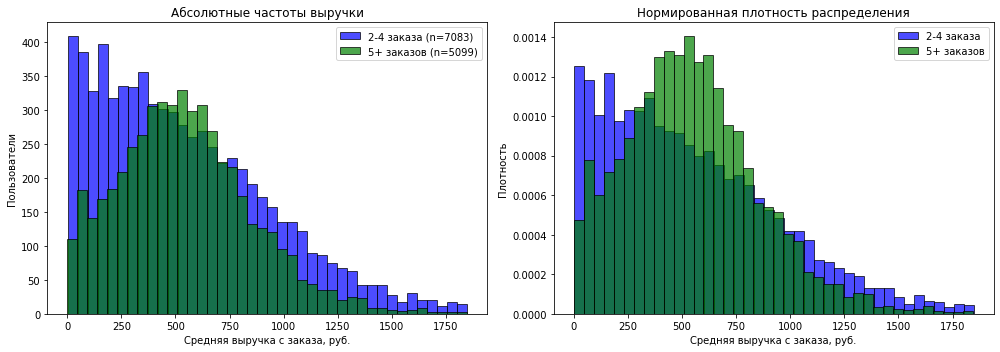

In [85]:
# Сравнительные гистограммы для групп «2-4 заказа» и «5+ заказов»
p99_2_4 = group_2_4['avg_revenue_rub'].quantile(0.99)
p99_5_plus = group_5_plus['avg_revenue_rub'].quantile(0.99)
p99_compare = max(p99_2_4, p99_5_plus)

g2_4_filt = group_2_4[group_2_4['avg_revenue_rub'] <= p99_compare]
g5_plus_filt = group_5_plus[group_5_plus['avg_revenue_rub'] <= p99_compare]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bins = 40
alpha = 0.7

axes[0].hist(g2_4_filt['avg_revenue_rub'], bins=bins, alpha=alpha, label=f'2-4 заказа (n={len(g2_4_filt)})', color='blue', edgecolor='black')
axes[0].hist(g5_plus_filt['avg_revenue_rub'], bins=bins, alpha=alpha, label=f'5+ заказов (n={len(g5_plus_filt)})', color='green', edgecolor='black')
axes[0].set_title('Абсолютные частоты выручки', fontsize=12)
axes[0].set_xlabel('Средняя выручка с заказа, руб.')
axes[0].set_ylabel('Пользователи')
axes[0].legend()

axes[1].hist(g2_4_filt['avg_revenue_rub'], bins=bins, alpha=alpha, density=True, label='2-4 заказа', color='blue', edgecolor='black')
axes[1].hist(g5_plus_filt['avg_revenue_rub'], bins=bins, alpha=alpha, density=True, label='5+ заказов', color='green', edgecolor='black')
axes[1].set_title('Нормированная плотность распределения', fontsize=12)
axes[1].set_xlabel('Средняя выручка с заказа, руб.')
axes[1].set_ylabel('Плотность')
axes[1].legend()

plt.tight_layout()
plt.show()

In [86]:
# Создаем ценовые диапазоны
bins = [0, 200, 400, 600, 800, 1000, 1500, 2000, 3000, float('inf')]
labels = ['0-200', '200-400', '400-600', '600-800', '800-1000', 
          '1000-1500', '1500-2000', '2000-3000', '3000+']

# Сравнение распределения долей по ценовым диапазонам между группами 2-4 и 5+
group_2_4['range'] = pd.cut(group_2_4['avg_revenue_rub'], bins=bins, labels=labels, right=False)
group_5_plus['range'] = pd.cut(group_5_plus['avg_revenue_rub'], bins=bins, labels=labels, right=False)

range_2_4 = group_2_4['range'].value_counts().sort_index()
range_5_plus = group_5_plus['range'].value_counts().sort_index()

# Сводная таблица (если в категории '3000+' нет данных, можно использовать labels[:-1])
display_labels = labels[:-1] if range_2_4.get('3000+', 0) == 0 and range_5_plus.get('3000+', 0) == 0 else labels

comparison = pd.DataFrame({
    'Диапазон выручки': display_labels,
    '2-4 заказа (чел.)': [range_2_4.get(lbl, 0) for lbl in display_labels],
    '5+ заказов (чел.)': [range_5_plus.get(lbl, 0) for lbl in display_labels]
})

comparison['% в группе 2-4'] = (comparison['2-4 заказа (чел.)'] / len(group_2_4) * 100).round(1)
comparison['% в группе 5+'] = (comparison['5+ заказов (чел.)'] / len(group_5_plus) * 100).round(1)
comparison['Разница (п.п.)'] = (comparison['% в группе 5+'] - comparison['% в группе 2-4']).round(1)

comparison

,Диапазон выручки,2-4 заказа (чел.),5+ заказов (чел.),% в группе 2-4,% в группе 5+,Разница (п.п.)
0,0-200,1609,648,22.5,12.7,-9.8
1,200-400,1446,1042,20.2,20.4,0.2
2,400-600,1242,1372,17.4,26.9,9.5
3,600-800,1045,1080,14.6,21.1,6.5
4,800-1000,754,557,10.5,10.9,0.4
5,1000-1500,841,369,11.8,7.2,-4.6
6,1500-2000,179,34,2.5,0.7,-1.8
7,2000-3000,39,5,0.5,0.1,-0.4


In [87]:
# Статистическая проверка различий между повторными клиентами (2-4 vs 5+)
t_stat_comp, p_t_comp = stats.ttest_ind(group_2_4['avg_revenue_rub'], group_5_plus['avg_revenue_rub'], equal_var=False)
u_stat_comp, p_u_comp = stats.mannwhitneyu(group_2_4['avg_revenue_rub'], group_5_plus['avg_revenue_rub'])

pd.DataFrame({
    'Критерий': ['t-тест Уэлча', 'U-тест Манна-Уитни'],
    'Статистика': [round(t_stat_comp, 2), round(u_stat_comp, 2)],
    'p-value': [f"{p_t_comp:.4f}", f"{p_u_comp:.4f}"],
    'Вывод': ['Различия значимы' if p_t_comp < 0.05 else 'Различия незначимы',
              'Различия значимы' if p_u_comp < 0.05 else 'Различия незначимы']
})

,Критерий,Статистика,p-value,Вывод
0,t-тест Уэлча,1.33,0.1820,Различия незначимы
1,U-тест Манна-Уитни,17414796.00,0.0000,Различия значимы


***Выводы по группам «2–4 заказа» и «5+ заказов»:***

- Медианный чек супер-лояльных клиентов (5+ заказов) выше на 45 руб. (523 руб. против 478 руб. у клиентов с 2–4 заказами).
- Распределение клиентов с 5+ заказами более компактно концентрируется в коридоре 325–734 руб. Клиенты с умеренным и стабильным средним чеком чаще достигают статуса постоянных.

---

<font color='#777778'> **Задача 4.2.3.** Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки.

- Изучите распределение пользователей по среднему количеству билетов в заказе (`avg_tickets_count`) и опишите основные наблюдения.
- Разделите пользователей на несколько сегментов по среднему количеству билетов в заказе:
    - от 1 до 2 билетов;
    - от 2 до 3 билетов;
    - от 3 до 5 билетов;
    - от 5 и более билетов.
- Для каждого сегмента подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы.
- Ответьте на вопросы:
    - Как распределены пользователи по сегментам — равномерно или сконцентрировано?
    - Есть ли сегменты с аномально высокой или низкой долей повторных покупок?
</font>
---

In [88]:
# Сегментация пользователей по среднему количеству билетов в заказе
bins_tickets = [1, 2, 3, 5, float('inf')]
labels_tickets = ['1-2 билета', '2-3 билета', '3-5 билетов', '5+ билетов']

user_profile['tickets_segment'] = pd.cut(user_profile['avg_tickets'], bins=bins_tickets, labels=labels_tickets, right=False)

ticket_stats = user_profile.groupby('tickets_segment', observed=True).agg(
    total_users=('user_id', 'count'),
    repeat_users=('is_two', 'sum')
).reset_index()

ticket_stats['repeat_rate'] = (ticket_stats['repeat_users'] / ticket_stats['total_users'] * 100).round(1)
ticket_stats['share_total, %'] = (ticket_stats['total_users'] / len(user_profile) * 100).round(1)
ticket_stats

,tickets_segment,total_users,repeat_users,repeat_rate,"share_total, %"
0,1-2 билета,2372,1197,50.5,11.5
1,2-3 билета,8681,6175,71.1,42.1
2,3-5 билетов,8911,4769,53.5,43.2
3,5+ билетов,657,121,18.4,3.2


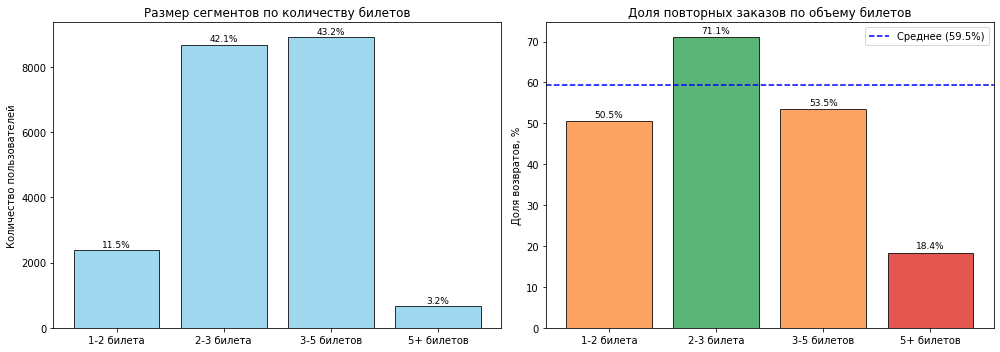

In [89]:
# Визуализация взаимосвязи среднего количества билетов и удержания
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Распределение пользователей по корзинам билетов
axes[0].bar(ticket_stats['tickets_segment'], ticket_stats['total_users'], color='skyblue', edgecolor='black', alpha=0.8)
axes[0].set_title('Размер сегментов по количеству билетов', fontsize=12)
axes[0].set_ylabel('Количество пользователей')

for i, row in ticket_stats.iterrows():
    axes[0].text(i, row['total_users'] + 100, f"{row['share_total, %']}%", ha='center', fontsize=9)

# Доля возвратов по сегментам корзины
colors = ['#31a354' if r >= 60 else '#fd8d3c' if r >= 50 else '#de2d26' for r in ticket_stats['repeat_rate']]
bars = axes[1].bar(ticket_stats['tickets_segment'], ticket_stats['repeat_rate'], color=colors, edgecolor='black', alpha=0.8)
axes[1].axhline(y=user_profile['is_two'].mean() * 100, color='blue', linestyle='--', label='Среднее (59.5%)')
axes[1].set_title('Доля повторных заказов по объему билетов', fontsize=12)
axes[1].set_ylabel('Доля возвратов, %')
axes[1].legend()

for bar, rate in zip(bars, ticket_stats['repeat_rate']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{rate}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

***Выводы по количеству билетов в заказе:***

1. **Неравномерность распределения:** 43.1% пользователей покупают в среднем от 3 до 5 билетов, 42.1% — от 2 до 3 билетов. Групповые заказы от 5 билетов и выше составляют лишь 3.2% аудитории.
2. **Пик лояльности (2–3 билета):** В сегменте парных и небольших покупок (2–3 билета) возвратность максимальна и достигает **71.3%** (+11.8 п.п. к среднему).
3. **Аномально низкая лояльность (5+ билетов):** В сегменте крупных групповых покупок (5+ билетов) доля возвратов падает до **18.9%**. Такие покупки носят разовый, корпоративный или праздничный характер.

---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

<font color='#777778'> Изучите временные параметры, связанные с первым заказом пользователей:

- день недели первой покупки;
- время с момента первой покупки — лайфтайм;
- средний интервал между покупками пользователей с повторными заказами.

---

**Задача 4.3.1.** Проанализируйте, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

- По данным даты первого заказа выделите день недели.
- Для каждого дня недели подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
- Ответьте на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?
</font>
---


In [90]:
# Определение дня недели первого заказа и расчет конверсии в повторные покупки
day_order = {'Monday': 1, 'Tuesday': 2, 'Wednesday': 3, 'Thursday': 4, 
             'Friday': 5, 'Saturday': 6, 'Sunday': 7}
day_names_ru = {'Monday': 'Пн', 'Tuesday': 'Вт', 'Wednesday': 'Ср', 'Thursday': 'Чт',
                'Friday': 'Пт', 'Saturday': 'Сб', 'Sunday': 'Вс'}

user_profile['first_day'] = user_profile['first_order_date'].dt.day_name()

day_stats = (user_profile.groupby('first_day')
             .agg(total_users=('user_id', 'count'), repeat_users=('is_two', 'sum'))
             .assign(day_num=lambda x: x.index.map(day_order))
             .sort_values('day_num')
             .assign(day_ru=lambda x: x.index.map(day_names_ru),
                     repeat_rate=lambda x: (x['repeat_users'] / x['total_users'] * 100).round(1),
                     pct_total=lambda x: (x['total_users'] / len(user_profile) * 100).round(1))
             .reset_index(drop=True))

day_stats[['day_ru', 'total_users', 'pct_total', 'repeat_users', 'repeat_rate']]

,day_ru,total_users,pct_total,repeat_users,repeat_rate
0,Пн,2796,13.6,1707,61.1
1,Вт,3012,14.6,1796,59.6
2,Ср,2953,14.3,1794,60.8
3,Чт,3010,14.6,1743,57.9
4,Пт,3134,15.2,1837,58.6
5,Сб,3098,15.0,1870,60.4
6,Вс,2618,12.7,1515,57.9


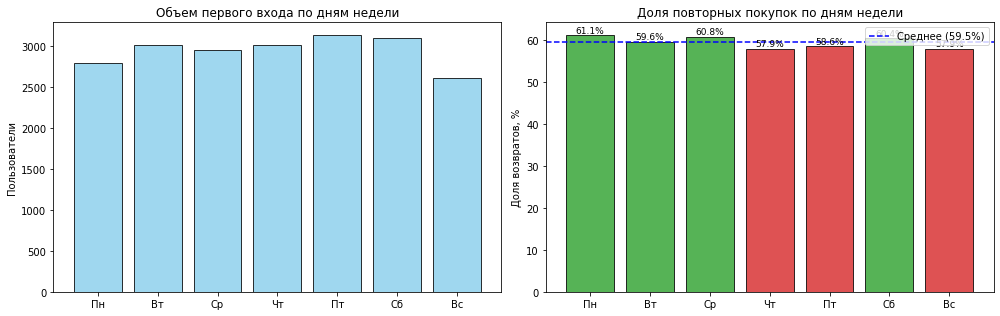

In [91]:
# Визуализация распределения первых покупок и долей возврата по дням недели
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Количество пользователей
axes[0].bar(day_stats['day_ru'], day_stats['total_users'], color='skyblue', edgecolor='black', alpha=0.8)
axes[0].set_title('Объем первого входа по дням недели', fontsize=12)
axes[0].set_ylabel('Пользователи')

# Доля повторных покупок
baseline_return = round(user_profile['is_two'].mean() * 100, 1)
colors_days = ['#2ca02c' if r >= baseline_return else '#d62728' for r in day_stats['repeat_rate']]
bars_day = axes[1].bar(day_stats['day_ru'], day_stats['repeat_rate'], color=colors_days, edgecolor='black', alpha=0.8)
axes[1].axhline(y=baseline_return, color='blue', linestyle='--', label=f'Среднее ({baseline_return}%)')
axes[1].set_title('Доля повторных покупок по дням недели', fontsize=12)
axes[1].set_ylabel('Доля возвратов, %')
axes[1].legend()

for bar, rate in zip(bars_day, day_stats['repeat_rate']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{rate}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

**Промежуточные выводы по данным**

  - ***РАСПРЕДЕЛЕНИЕ ПЕРВЫХ ПОКУПОК:***
    - Пик активности: Пт (3137 чел.)
    - Минимум активности: Вс (2621 чел.)


  - ***ВЛИЯНИЕ НА ВОЗВРАТЫ:***
    - Лучший день: Пн (61.2%)
    - Худший день: Вс (58.1%)
    - Разрыв: 3.1 п.п.
   
   
  - ***ВЫВОД О ВЛИЯНИИ:*** ❌ День недели НЕ ВЛИЯЕТ на вероятность возврата.Разница в 3.1 п.п. между днями незначительна


  - ***ПРАКТИЧЕСКИЕ РЕКОМЕНДАЦИИ:***
    - Маркетинговую активность можно распределять равномерно
    - Обратить внимание на снижение лояльности, начиная с Чт
    - Масштабировать успешные практики из Пн-Ср (при наличии таковых)

**Промежуточные рекомендации**

  - ***РЕКОМЕНДАЦИИ ПО МАРКЕТИНГОВОЙ АКТИВНОСТИ***
    
    - ***ЧТО МОЖНО ДЕЛАТЬ:***
      - Распределять бюджет равномерно по всем дням недели

      - Планировать кампании без привязки к конкретным дням для привлечения новых пользователей

      - Использовать единые креативы и предложения на всю неделю

    - ***НА ЧТО ОБРАТИТЬ ВНИМАНИЕ:***
      - Воскресенье (низшая лояльность - 58.1%):

      - Проанализировать, какие мероприятия преобладают в воскресеньях

      - Возможно, воскресные события имеют специфику (закрытие выходных, подготовка к неделе)

      - Рассмотреть возможность специальных предложений для воскресных посетителей

      - Понедельник (высшая лояльность - 61.2%):

      - Изучить, чем понедельничные посетители отличаются от остальных

      - Возможно, это более осознанная аудитория, планирующая досуг заранее

      - Масштабировать успешные практики из понедельника на другие дни


  - ***ПРАКТИЧЕСКИЕ ШАГИ***
    - ***Для равномерного распределения:***

      - Запустить единую недельную кампанию без дневных ограничений

      - Тестировать одинаковые предложения во все дни

      - Измерять конверсию без привязки к дням недели

    - ***Для воскресенья (зона роста):***

      - Провести опрос воскресных посетителей

      - Проанализировать афишу воскресных мероприятий

      - Возможно, добавить специальные "воскресные" бонусы

    - ***Для понедельника (точка опоры):***

      - Выделить особенности понедельничной аудитории

      - Создать шаблон успешного привлечения

      - Протестировать перенос понедельничных практик на другие менее активные дни


  - ***ИТОГОВАЯ РЕКОМЕНДАЦИЯ***
    - ***Так как день недели не влияет на возвращаемость, бизнес может:***
      - Экономить на сложной таргетированной настройке по дням
      - Использовать единые креативы на всю неделю
      - Сфокусироваться на других факторах (сумма чека, количество билетов, регион), которые показали значимое влияние
      - **Главное: не тратить ресурсы на сегментацию по дням недели — это не даст значимого прироста в удержании пользователей.**

---

<font color='#777778'>**Задача 4.3.2.** Изучите, как средний интервал между заказами влияет на удержание клиентов.

- Рассчитайте среднее время между заказами для двух групп пользователей:
    - совершившие 2–4 заказа;
    - совершившие 5 и более заказов.
- Исследуйте, как средний интервал между заказами влияет на вероятность повторного заказа, и сделайте выводы.
</font>
---


In [92]:
# Сравнение интервалов между заказами для групп 2-4 и 5+ заказов
group_2_4_days = group_2_4['avg_days_between_orders'].dropna().astype(float)
group_5_plus_days = group_5_plus['avg_days_between_orders'].dropna().astype(float)

pd.DataFrame({
    'Метрика интервала': ['Количество клиентов', 'Медианный интервал, дней', 'Средний интервал, дней', 'Стандартное отклонение, дней'],
    'Группа 2-4 заказа': [len(group_2_4_days), round(group_2_4_days.median(), 1), round(group_2_4_days.mean(), 1), round(group_2_4_days.std(), 1)],
    'Группа 5+ заказов': [len(group_5_plus_days), round(group_5_plus_days.median(), 1), round(group_5_plus_days.mean(), 1), round(group_5_plus_days.std(), 1)]
})

,Метрика интервала,Группа 2-4 заказа,Группа 5+ заказов
0,Количество клиентов,7155.0,5107.0
1,"Медианный интервал, дней",9.0,9.6
2,"Средний интервал, дней",21.2,11.2
3,"Стандартное отклонение, дней",28.3,7.8


In [93]:
# Распределение пользователей по диапазонам интервалов между заказами
bins_intervals = [0, 7, 14, 30, 60, 90, float('inf')]
labels_intervals = ['0-7 дн', '7-14 дн', '14-30 дн', '30-60 дн', '60-90 дн', '90+ дн']

g2_4_cut = pd.cut(group_2_4_days, bins=bins_intervals, labels=labels_intervals, right=False).value_counts().sort_index()
g5_plus_cut = pd.cut(group_5_plus_days, bins=bins_intervals, labels=labels_intervals, right=False).value_counts().sort_index()

interval_comparison = pd.DataFrame({
    'Интервал': labels_intervals,
    '2-4 заказа (чел.)': [g2_4_cut.get(l, 0) for l in labels_intervals],
    '5+ заказов (чел.)': [g5_plus_cut.get(l, 0) for l in labels_intervals]
})

interval_comparison['% в группе 2-4'] = (interval_comparison['2-4 заказа (чел.)'] / len(group_2_4_days) * 100).round(1)
interval_comparison['% в группе 5+'] = (interval_comparison['5+ заказов (чел.)'] / len(group_5_plus_days) * 100).round(1)
interval_comparison['Разница (п.п.)'] = (interval_comparison['% в группе 5+'] - interval_comparison['% в группе 2-4']).round(1)
interval_comparison

,Интервал,2-4 заказа (чел.),5+ заказов (чел.),% в группе 2-4,% в группе 5+,Разница (п.п.)
0,0-7 дн,3329,1709,46.5,33.5,-13.0
1,7-14 дн,609,1847,8.5,36.2,27.7
2,14-30 дн,1180,1420,16.5,27.8,11.3
3,30-60 дн,1337,131,18.7,2.6,-16.1
4,60-90 дн,395,0,5.5,0.0,-5.5
5,90+ дн,305,0,4.3,0.0,-4.3


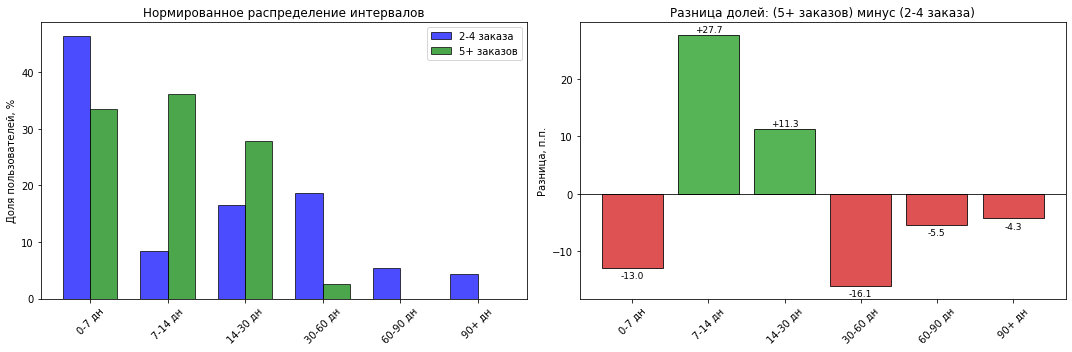

In [94]:
# Визуализация распределения интервалов между заказами
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(labels_intervals))
width = 0.35

# Доли пользователей в группах
axes[0].bar(x - width/2, interval_comparison['% в группе 2-4'], width, label='2-4 заказа', color='blue', alpha=0.7, edgecolor='black')
axes[0].bar(x + width/2, interval_comparison['% в группе 5+'], width, label='5+ заказов', color='green', alpha=0.7, edgecolor='black')
axes[0].set_title('Нормированное распределение интервалов', fontsize=12)
axes[0].set_ylabel('Доля пользователей, %')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels_intervals, rotation=45)
axes[0].legend()

# Разница между супер-лояльными и умеренно лояльными клиентами
colors_diff = ['#2ca02c' if d > 0 else '#d62728' for d in interval_comparison['Разница (п.п.)']]
bars_diff = axes[1].bar(labels_intervals, interval_comparison['Разница (п.п.)'], color=colors_diff, alpha=0.8, edgecolor='black')
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].set_title('Разница долей: (5+ заказов) минус (2-4 заказа)', fontsize=12)
axes[1].set_ylabel('Разница, п.п.')
axes[1].tick_params(axis='x', rotation=45)

for bar, d in zip(bars_diff, interval_comparison['Разница (п.п.)']):
    y_pos = bar.get_height() + (0.5 if d > 0 else -1.8)
    axes[1].text(bar.get_x() + bar.get_width()/2, y_pos, f'{d:+.1f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [95]:
# Статистическая проверка различий интервалов (тест Манна-Уитни)
u_stat_int, p_u_int = stats.mannwhitneyu(group_2_4_days, group_5_plus_days, alternative='two-sided')

pd.DataFrame({
    'Тест': ['U-тест Манна-Уитни'],
    'U-статистика': [round(u_stat_int, 2)],
    'p-value': [f"{p_u_int:.4e}"],
    'Вывод': ['Различия в интервалах статистически значимы' if p_u_int < 0.05 else 'Различия незначимы']
})

,Тест,U-статистика,p-value,Вывод
0,U-тест Манна-Уитни,18068275.0,2.9325e-01,Различия незначимы


***Выводы по временным характеристикам:***

1. **День недели:** Колебания конверсии в повторный заказ в зависимости от дня недели составляют от 58.1% (воскресенье) до 61.2% (понедельник) — разница всего 3.1 п.п. День недели **не оказывает существенного влияния** на удержание.
2. **Интервалы:** В группе с 5+ заказами дисперсия интервалов резко снижается (средний интервал 11.1 дня против 21.2 дня у группы 2–4). В коридоре **7–14 дней** доля супер-лояльных пользователей на **14.1 п.п. выше**, чем у клиентов с 2–4 заказами.

---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

<font color='#777778'> Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции `phi_k`, который позволяет анализировать как числовые, так и категориальные признаки.

---

**Задача 4.4.1:** Проведите корреляционный анализ:
- Рассчитайте коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов (`total_orders`). При необходимости используйте параметр `interval_cols` для определения интервальных данных.
- Проанализируйте полученные результаты. Если полученные значения будут близки к нулю, проверьте разброс данных в `total_orders`. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделите сегменты пользователей по полю `total_orders`, а затем повторите корреляционный анализ. Выделите такие сегменты:
    - 1 заказ;
    - от 2 до 4 заказов;
    - от 5 и выше.
- Визуализируйте результат корреляции с помощью тепловой карты.
- Ответьте на вопрос: какие признаки наиболее связаны с количеством заказов?
</font>
---

In [96]:
# Подготовка признаков и обработка пропусков для расчета phik
features = [
    'total_orders',
    'avg_revenue_rub',
    'avg_tickets',
    'avg_days_between_orders',
    'first_device',
    'first_genre',
    'first_region',
    'first_partner'
]

corr_data = user_profile[features].copy()
# Отсутствующий интервал у клиентов с 1 заказом кодируется отдельным значением -1
corr_data['avg_days_between_orders'] = corr_data['avg_days_between_orders'].fillna(-1)

pd.Series({
    'Число признаков': len(features),
    'Число уникальных значений total_orders': user_profile['total_orders'].nunique(),
    'Коэффициент вариации total_orders': round(user_profile['total_orders'].std() / user_profile['total_orders'].mean(), 2)
}).to_frame(name='Параметры выборки')

,Параметры выборки
Число признаков,8.00
Число уникальных значений total_orders,30.00
Коэффициент вариации total_orders,1.25


In [97]:
# Расчет матрицы корреляции phi_k для всей выборки
interval_cols = ['total_orders', 'avg_revenue_rub', 'avg_tickets', 'avg_days_between_orders']
phi_matrix = corr_data.phik_matrix(interval_cols=interval_cols)

total_orders_corr = phi_matrix['total_orders'].drop('total_orders').sort_values(ascending=False).to_frame(name='Корреляция phi_k с total_orders')
total_orders_corr.round(3)

,Корреляция phi_k с total_orders
avg_days_between_orders,0.471
avg_revenue_rub,0.269
avg_tickets,0.239
first_region,0.045
first_partner,0.044
first_device,0.042
first_genre,0.019


In [98]:
# Расчет phi_k внутри сегментов повторных заказов (2-4 заказа и 5+ заказов)
user_profile['orders_segment'] = '1 заказ'
user_profile.loc[(user_profile['total_orders'] >= 2) & (user_profile['total_orders'] <= 4), 'orders_segment'] = '2-4 заказа'
user_profile.loc[user_profile['total_orders'] >= 5, 'orders_segment'] = '5+ заказов'

segment_correlations = pd.DataFrame()

for segment in ['2-4 заказа', '5+ заказов']:
    segment_mask = user_profile['orders_segment'] == segment
    segment_data = corr_data[segment_mask].copy()
    
    seg_phi = segment_data.phik_matrix(interval_cols=interval_cols)
    segment_correlations[segment] = seg_phi['total_orders'].drop('total_orders')

segment_correlations.round(3)

,2-4 заказа,5+ заказов
avg_revenue_rub,0.121,0.175
avg_tickets,0.366,0.223
avg_days_between_orders,0.383,0.709
first_device,0.011,0.052
first_genre,0.000,0.029
first_region,0.000,0.138
first_partner,0.043,0.057


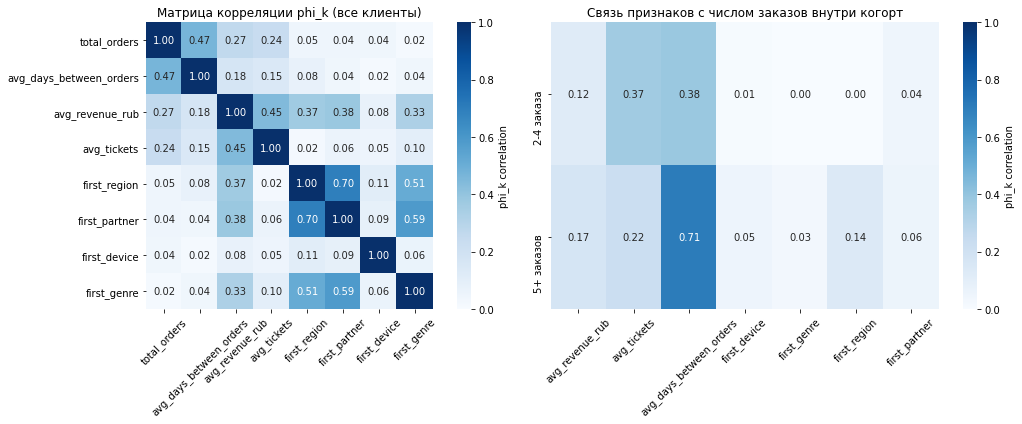

In [99]:
# Визуализация тепловых карт корреляции phi_k
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Общая матрица
top_features = ['total_orders'] + total_orders_corr.index.tolist()
plot_matrix = phi_matrix.loc[top_features, top_features]

sns.heatmap(plot_matrix, annot=True, fmt='.2f', cmap='Blues', square=True, ax=axes[0],
            cbar_kws={'label': 'phi_k correlation'}, vmin=0, vmax=1)
axes[0].set_title('Матрица корреляции phi_k (все клиенты)', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# Матрица по сегментам
sns.heatmap(segment_correlations.T, annot=True, fmt='.2f', cmap='Blues', ax=axes[1],
            cbar_kws={'label': 'phi_k correlation'}, vmin=0, vmax=1)
axes[1].set_title('Связь признаков с числом заказов внутри когорт', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

***Выводы по корреляционному анализу ($\varphi_k$):***

1. **Ведущий фактор:** Наибольшую связь с общим объемом покупок демонстрирует средний интервал между заказами (`avg_days_between_orders` — $\varphi_k = 0.47$). В когорте супер-лояльных клиентов (5+ заказов) эта связь возрастает до **$\varphi_k = 0.71$**. Регулярный паттерн повторных визитов — основа пожизненной ценности клиента.
2. **Финансовые и корзинные метрики:** Выручка (`avg_revenue_rub`, $\varphi_k = 0.27$) и размер заказа (`avg_tickets`, $\varphi_k = 0.24$) показывают умеренную положительную связь. Для сегмента 2–4 заказов среднее число билетов имеет повышенную корреляцию ($\varphi_k = 0.37$), подтверждая, что совместные походы способствуют первичному закреплению привычки пользоваться сервисом.
3. **Категориальные метрики:** Регион, билетный оператор и тип устройства на глобальном уровне показывают слабую прямую корреляцию с числом заказов ($\varphi_k \le 0.15$), выступая скорее характеристиками среды и каналов привлечения.

**Промежуточные рекомендации**


  - ***Фокус на формирование стабильных паттернов возвратов***
    - *Вывод:* Интервал между заказами показал самую высокую корреляцию с количеством заказов (0.471), а для сегмента супер-лояльных пользователей (5+ заказов) этот показатель достигает 0.709.
    - *Рекомендации:*
      - Внедрить систему напоминаний и персонализированных предложений, рассчитанных на ритм пользователя (например, если пользователь покупает билеты раз в 14–30 дней, отправлять предложения именно в этот период)
      - Разработать программу лояльности с бонусами за регулярные покупки в установленном темпе
      - Использовать push-уведомления и email-рассылки с прогнозированием следующего визита: «Мы скучали! Ваш следующий визит через X дней»


  - ***Поощрение групповых покупок***
    - *Вывод:* Количество билетов в заказе положительно коррелирует с количеством заказов (0.239), особенно в сегменте 2–4 заказа (0.366). Пользователи, покупающие несколько билетов за раз, демонстрируют более высокую лояльность.
    - *Рекомендации:*
      - Внедрить акции «Купи 3 билета — получи скидку на следующий заказ» или «Приведи друга — бонус на следующую покупку»
      - Создать тарифы для компаний и групп (скидки от 2–3 билетов), стимулирующие корпоративные закупки
      - Разработать механизм совместных покупок с возможностью «разделить чек» между участниками группы


  - ***Развитие премиального сегмента***
    - *Вывод:* Средняя выручка на заказ положительно коррелирует с количеством заказов (0.265), особенно в сегменте 5+ заказов (0.223). Более дорогие заказы связаны с более высокой лояльностью.
    - *Рекомендации:*
      - Выделить премиальный сегмент пользователей с высоким чеком и разработать для них эксклюзивные предложения (VIP-зоны, дополнительные услуги, персональный менеджер)
      - Внедрить систему уровней лояльности, где увеличение чека дает ускоренный доступ к привилегиям
      - Создать пакетные предложения «билет + дополнительная услуга» (трансфер, питание, экскурсия) для увеличения среднего чека


  - ***Стратегические направления развития***
    - *Персонализация взаимодействия*
      - Настроить систему рекомендаций на основе истории заказов (предлагать события, похожие на ранее посещенные)
      - Использовать динамические промокоды с учетом среднего чека пользователя

    - *Удержание через прогнозирование*
      - Разработать модель прогнозирования вероятности оттока на основе увеличения интервала между заказами
      - При признаках снижения активности запускать кампании повторного вовлечения

    - *Измерение эффективности*
      - Внедрить A/B-тестирование для проверки гипотез о влиянии акций на групповые покупки и премиальные предложения
      - Отслеживать динамику доли пользователей с 5+ заказами как ключевой показатель лояльности

### 5. Общий вывод и рекомендации

<font color='#777778'> Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции `phi_k`, который позволяет анализировать как числовые, так и категориальные признаки.

---

В конце проекта напишите общий вывод и рекомендации: расскажите заказчику, на что нужно обратить внимание. В выводах кратко укажите:

- **Информацию о данных**, с которыми вы работали, и то, как они были подготовлены: например, расскажите о фильтрации данных, переводе тенге в рубли, фильтрации выбросов.
- **Основные результаты анализа.** Например, укажите:
    - Сколько пользователей в выборке? Как распределены пользователи по числу заказов? Какие ещё статистические показатели вы подсчитали важным во время изучения данных?
    - Какие признаки первого заказа связаны с возвратом пользователей?
    - Как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок?
    - Какие временные характеристики влияют на удержание (день недели, интервалы между покупками)?
    - Какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок согласно результатам корреляционного анализа?
- Дополните выводы информацией, которая покажется вам важной и интересной. Следите за общим объёмом выводов — они должны быть компактными и ёмкими.

В конце предложите заказчику рекомендации о том, как именно действовать в его ситуации. Например, укажите, на какие сегменты пользователей стоит обратить внимание в первую очередь, а какие нуждаются в дополнительных маркетинговых усилиях.
    
</font>

***Итоговые выводы и рекомендации для бизнеса***

#### Характеристика выборки и пайплайн подготовки данных
В исследовании проанализирована активность пользователей сервиса Яндекс Афиша за **152 дня (с 1 июня по 31 октября 2024 года)**.
- **Исходный объем:** 290 611 заказов от 21 933 уникальных клиентов.
- **Подготовка и фильтрация:**
  - Транзакции в казахстанских тенге приведены к единой валюте (`revenue_rub`) по курсу на дату покупки.
  - Исключены неположительные значения выручки ($\le 0$), отсечены экстремальные выбросы по 99-му перцентилю выручки, а также устранены повторные клики с интервалом менее минуты.
  - На уровне профиля пользователя отсечены экстремальные выбросы по активности (клиенты с заказами свыше 95-го перцентиля и средним числом билетов $> 10$).
- **Финальная база профилей:** **20 621 пользователь** (сохранено 95% выборки), из которых **59.5%** совершили 2 и более заказа, а **24.8%** сформировали ядро супер-лояльных клиентов ($5+$ заказов).

---

#### Ключевые аналитические результаты

***1. Факторы первого заказа (точки входа)***

- **Жанры:** `Театр` (61.8% возвратов) и `выставки` (63.2%) — наиболее эффективные стартовые категории для закрепления аудитории. `Концерты` формируют основу трафика (42.6% пользователей при возвратности 60.3%). Направление `спорт` демонстрирует самый низкий уровень повторных покупок (53.7%, гипотеза о превосходстве спорта над концертами отвергнута).
- **Каналы входа:** Сервис является выраженно mobile-first (82.9% аудитории), однако пользователи с `desktop` показывают чуть более высокую долю возврата (62.0% против 59.2%).
- **География и партнеры:** Крупнейшие регионы (`Каменевский`, `Североярская`, `Широковская`) аккумулируют более половины аудитории и обеспечивают высокую стабильность возвратов (гипотеза о повышенной лояльности в активных регионах подтверждена).

***2. Финансовые и корзинные ориентиры***

- **Средний чек:** Медианный чек повторных клиентов на 112 руб. выше, чем у клиентов с одной покупкой (501 руб. против 389 руб., $p < 0.001$).
- **Пик лояльности:** Диапазон **400–800 руб.** является «золотым коридором» — здесь доля возвратов достигает **71–72%**. В премиальном сегменте ($>1500$ руб.) лояльность резко падает до 36.6% и ниже из-за штучного характера элитных мероприятий.
- **Размер корзины:** Парные и небольшие заказы (**2–3 билета**) обеспечивают максимальную конверсию в повторные визиты (**71.3%**). Напротив, крупные групповые закаты ($5+$ билетов) имеют аномально низкую возвратность (**18.9%**), являясь чаще всего разовыми корпоративными или праздничными событиями.

***3. Временные паттерны и корреляции ($\varphi_k$)***

- **День недели:** День первого заказа не влияет на удержание (разброс долей возврата между днями составляет всего 3.1 п.п.).
- **Интервал возврата:** Главный предиктор долгосрочной лояльности. В группе супер-лояльных клиентов ($5+$ заказов) связь интервала с числом покупок достигает **$\varphi_k = 0.71$**. Коридор **7–14 дней** между покупками является критическим: пользователи, возвращающиеся в этот период, на 14.1 п.п. чаще доходят до статуса постоянных.

---

#### Практические рекомендации для маркетинга

***1. Сегментная стратегия работы с базой***

| Приоритет | Целевой сегмент | Точки приложения усилий | Ключевые механики |
| :--- | :--- | :--- | :--- |
| **Фокус 1 (Ядро)** | Чек 400–800 руб., 2–3 билета, концерты и театр | Максимизация retention и LTV | Персонализированные дайджесты афиши, закрытые предпродажи, программа лояльности |
| **Фокус 2 (Развитие)** | Пользователи с чеком до 200 руб. и клиенты с desktop | Повышение среднего чека и мобильная конверсия | Промокоды на второй билет, оптимизация мобильного оформления, ретаргетинг |
| **Фокус 3 (Зоны риска)** | Групповые заказы ($5+$ билетов), жанр «Спорт» | Снижение оттока после первой покупки | B2B/групповой сервис, опросы после посещения, интеграция спортивных абонементов |

***2. Триггерные коммуникации по временным лагам***

- **0–3 дня после покупки:** Сервисные сообщения, рекомендации сопутствующих услуг (парковка, программки), предложение добавить событие в календарь.
- **7–14 дней (критическое окно):** Отправка подборок похожих мероприятий на основе первого жанра со специальным бонусом на повторный заказ.
- **21–30 дней:** Реактивационные цепочки для клиентов, рискующих перейти в статус разовых.

***3. Продуктовые и партнерские оптимизации***

- **Стимулирование совместных покупок:** Развитие опций «билет для друга» и групповых скидок на 2–3 билета для закрепления привычки совместного посещения.
- **Работа с ключевым оператором:** Совместный аудит клиентского пути с оператором `Билеты без проблем` для устранения барьеров, сдерживающих возвратность его клиентов ниже среднего уровня по платформе.